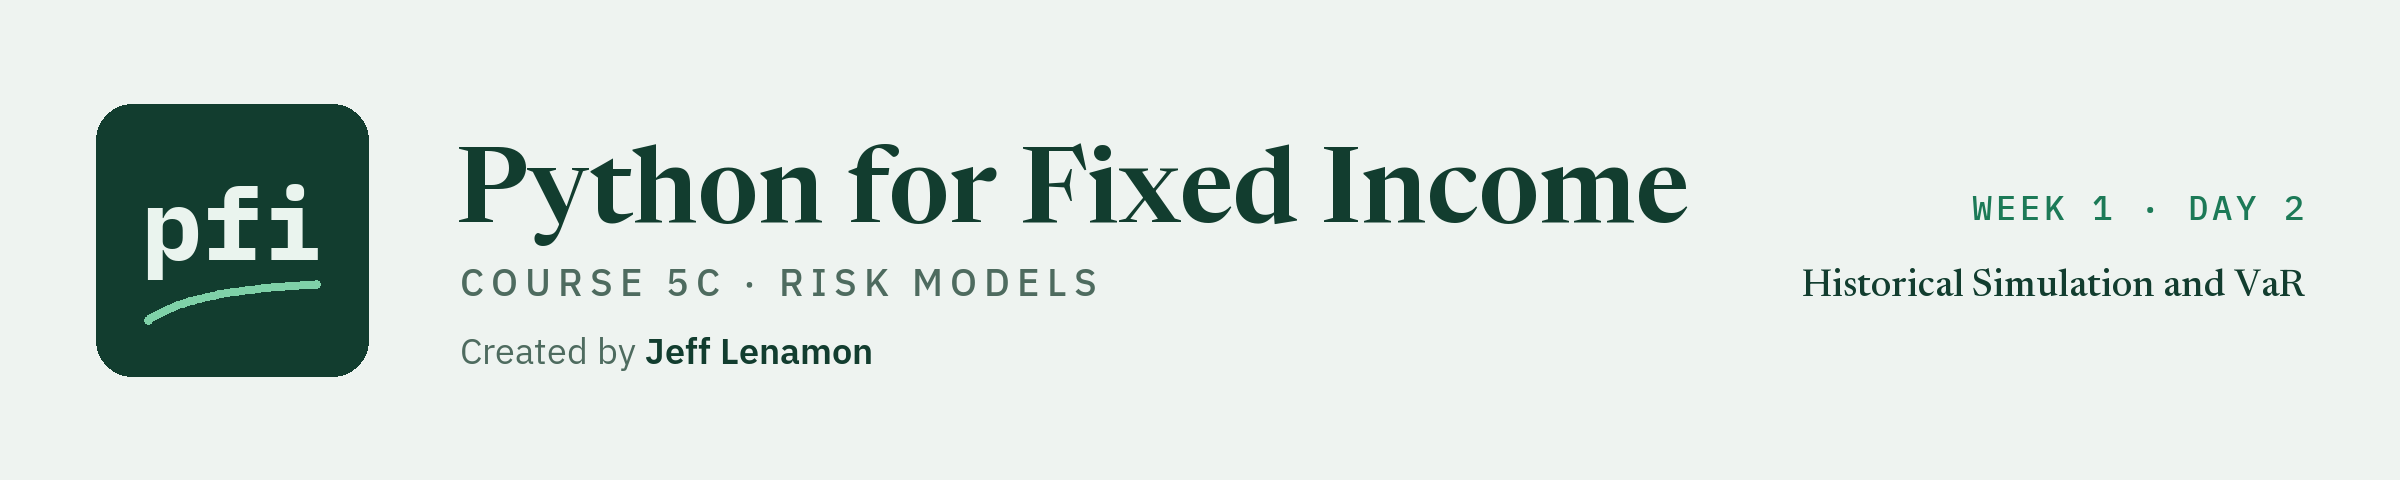

# Historical Simulation and VaR

Week 1, Day 2. The book's daily P&L had the past days repeated, its VaR and expected shortfall three ways, and a backtest that counts the days the VaR was wrong.

**Data:** `holdings.csv`, the course's book of 200 bonds as of 2026-09-30, with `ratings.csv` for the rating scale: **synthetic**, invented issuers and CUSIPs, no real company.

**Data:** `treasury_par_yields.csv`, 2,940 days of U.S. Treasury par yields, 2015-01-02 to 2026-10-02: **real**, U.S. Department of the Treasury, public domain.

**Data:** `course3_synthetic_spreads.csv`, 2,940 daily investment grade and high yield spreads in bp, one per date of the Treasury file: **synthetic**, invented for Course 3, not ICE, Moody's, or any index.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course05c_risk_models/week1/day2/02_historical_simulation_and_var.ipynb)

Day 1 simulated a loss from inputs chosen for the lesson. Today the inputs are the past: every daily move of the Treasury curve and the credit spread indexes from 2015 to 2022, applied one at a time to today's book. That is **historical simulation**, and the loss it reads off its worst days is the book's **VaR**.

* **The book is synthetic and held fixed.** `holdings.csv` is the course's book of 200 invented bonds as of 2026-09-30. Each past day's moves are applied to that same book: no bond matures, nothing is traded.
* **The moves are past data.** Treasury yields are the U.S. Treasury's own (real, public domain); the IG and HY spreads are Course 3's synthetic series. Only the development years, 2015-01-02 to 2022-12-30, are used. The held-out years stay closed until the capstone.
* **Names.** Every loss here is conditional: "had the daily moves of 2015 to 2022 repeated, with the book as of 2026-09-30 held fixed, the 99th percentile one-day loss was US$N". It is never a statement of what the book will lose.

Today you will:

1. Measure the book's exposure to rates and to spreads, tenor by tenor and grade by grade.
2. Turn each past day's moves into the book's P&L (`historical_pnl`), and check the rate part two ways.
3. Read VaR and expected shortfall off the worst days (`var_es`), and draw the tail.
4. Set a normal model and a Student's t Monte Carlo beside the historical numbers.
5. Read every setting: the level, the quantile method, the window, and the horizon.
6. Backtest: count the days a rolling VaR was beaten, and test the count with Kupiec's test (`kupiec_pof`).

Q. Set up today's work folder: the thread settings, the seed, the book, the curve, the spreads, and the modules.

## Before you start: install the libraries

Run this cell first. It checks that every library this course pins in its `requirements.txt` is installed and installs only what is missing, so it finishes in a second on a machine set up from the repo's `requirements.txt` and does the installing for you in Google Colab. If it installs anything in Colab, restart the session (Runtime, Restart session) and run the notebook again from the top.

In [1]:
# install what this notebook needs: the course's pinned libraries, only those not already present
import importlib.util
import subprocess
import sys

# import name: the pinned package, from course05c_risk_models/requirements.txt
NEEDED = {
    "arch": "arch==8.0.0",
    "catboost": "catboost==1.2.10",
    "imblearn": "imbalanced-learn==0.14.2",
    "ipykernel": "ipykernel==7.4.0",
    "ipywidgets": "ipywidgets==8.1.9",
    "jinja2": "jinja2==3.1.6",
    "lightgbm": "lightgbm==4.7.0",
    "matplotlib": "matplotlib==3.11.2",
    "numpy": "numpy==2.5.3",
    "openpyxl": "openpyxl==3.1.5",
    "optuna": "optuna==5.0.0",
    "pandas": "pandas==3.0.6",
    "pytest": "pytest==9.1.1",
    "sklearn": "scikit-learn==1.9.1",
    "scipy": "scipy==1.18.1",
    "shap": "shap==0.52.0",
    "statsmodels": "statsmodels==0.15.0",
    "xgboost": "xgboost==3.4.1",
}

# a package is present when Python can find its module; the version is left as the machine has it
missing = [pin for module, pin in NEEDED.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", *missing], check=True)
    print(f"{len(NEEDED)} packages checked, {len(missing)} installed: restart the session and run again from the top")
else:
    print(f"{len(NEEDED)} packages checked, all present")

18 packages checked, all present


In [2]:
# today's setup: the thread settings, the modules, the seed, the course data, and a fresh work folder
import os

# one thread for the maths libraries, so every run of the notebook gives the same last digits.
# These two lines must run before numpy, pandas, scipy, statsmodels, or scikit-learn is imported: if you ran another
# cell first, restart the kernel and run this cell first (in Colab: Runtime, Restart session).
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

import importlib
import importlib.metadata
import importlib.util
import platform
import shutil
import subprocess
import sys
import tempfile
import urllib.request
from pathlib import Path

# packages a Colab runtime or a new environment may lack: stop with the line that installs the missing one
for module_name, install_name in [("statsmodels", "statsmodels"), ("scipy", "scipy"), ("sklearn", "scikit-learn"), ("pytest", "pytest")]:
    if importlib.util.find_spec(module_name) is None:
        raise RuntimeError(f"{install_name} is not installed. Run  !pip install {install_name}  in a new cell, "
                           "then run this cell again.")

import numpy as np
import pandas as pd

# the versions the saved outputs of this notebook came from (course05c_risk_models/requirements.txt)
PINNED = {"numpy": "2.5.3", "pandas": "3.0.6", "scipy": "1.18.1", "statsmodels": "0.15.0", "scikit-learn": "1.9.1", "matplotlib": "3.11.2", "pytest": "9.1.1"}
installed = {name: importlib.metadata.version(name) for name in PINNED}
print(f"Python {platform.python_version()}; " + ", ".join(f"{name} {version}" for name, version in installed.items()))
different = [name for name in PINNED if installed[name] != PINNED[name]]
if different:
    print(f"Not the course's pinned version: {', '.join(different)}. Printed numbers may differ in the last digits from the saved notebook.")

# the seed: one number for every random choice the course makes, so every run makes the same choices
SEED = 42

# remember the notebook's own folder, so that running this cell again starts from the same place
if "notebook_folder" not in globals():
    notebook_folder = Path.cwd()

# 1. find the course data before moving: the repo's data folder on your machine, GitHub in Colab
RAW_DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"
local_data = (notebook_folder / ".." / ".." / ".." / "data").resolve()
on_github = not (local_data / "treasury_par_yields.csv").exists()

# 2. a fresh work folder for today, in the system temp folder, outside the course repo
work = Path(tempfile.mkdtemp(prefix="pfi_course5c_02_"))
os.chdir(work)

# 3. copy today's data files into the work folder
DATA_FILES = ["holdings.csv", "ratings.csv", "treasury_par_yields.csv", "course3_synthetic_spreads.csv"]
for name in DATA_FILES:
    if on_github:
        urllib.request.urlretrieve(RAW_DATA + name, work / name)
    else:
        shutil.copy(local_data / name, work / name)

# print the folder's name only: its full path would show your user name
print(f"Work folder: {work.name}, in your temp folder")
print(f"Data files from {'GitHub' if on_github else 'the data folder of the course repo'}: {', '.join(DATA_FILES)}")
print(f"SEED = {SEED}")

Python 3.13.8; numpy 2.5.3, pandas 3.0.6, scipy 1.18.1, statsmodels 0.15.0, scikit-learn 1.9.1, matplotlib 3.11.2, pytest 9.1.1
Work folder: pfi_course5c_02_tu6mjei4, in your temp folder
Data files from the data folder of the course repo: holdings.csv, ratings.csv, treasury_par_yields.csv, course3_synthetic_spreads.csv
SEED = 42


Q. Write `mlkit.py`, Course 4's complete module, unchanged. `riskkit` imports it.

In [3]:
%%writefile mlkit.py
"""mlkit: the small pieces of machine learning that scikit-learn leaves to the analyst, written down and tested.

Written day by day in Python for Fixed Income, Course 4: Machine Learning.

Conventions, the same in every function:
- The seed is 42 wherever a function takes one, so every run gives the same numbers.
- Spreads are in basis points (bp). A model of log_oas is fitted in natural logs of bp; its errors are reported
  in bp after exp, and exp of a fitted log is a median-type value, not a mean.
- The positive class is 1 (default, bankrupt). Precision, recall, and F1 are for class 1 only.
- A row is flagged when its model probability is at least the threshold (probability >= threshold).
- Rows that fit a model, rows that choose a setting, and rows that report a result are kept apart; the split
  functions here prove it with a check that stops.
- Inputs of the wrong shape, or empty inputs, raise ValueError with a message that says what was wrong.
"""
import numpy as np  # arrays and arithmetic
import pandas as pd  # tables with labels
from numpy.typing import ArrayLike  # a list, an array, or a pandas Series


def assert_disjoint(train_index: ArrayLike, test_index: ArrayLike) -> None:
    """Stop if any row label is in both the training rows and the test rows.

    Inputs: the labels (or positions) of the rows in each part, for example X_train.index and X_test.index.
    Output: None when the parts share no label.
    Convention: a row in both parts is a test row the model has already seen, which flatters every metric.
    Raises AssertionError naming how many labels are in both parts, and ValueError if either part is empty.
    """
    # the labels of each part as sets
    train = set(np.asarray(train_index).tolist())
    test = set(np.asarray(test_index).tolist())
    if not train or not test:
        raise ValueError("train_index and test_index must both hold at least one label")
    # the labels found in both parts
    shared = train & test
    if shared:
        raise AssertionError(f"{len(shared)} row labels are in both the training and the test rows")


def _as_1d_array(values: ArrayLike, name: str) -> np.ndarray:
    """Return `values` as a 1-D float array, or raise ValueError naming the input."""
    array = np.asarray(values, dtype=float)
    if array.ndim != 1:
        raise ValueError(f"{name} must be one-dimensional, not {array.ndim}-dimensional")
    if array.size == 0:
        raise ValueError(f"{name} is empty")
    return array


def regression_metrics(y_true: ArrayLike, y_fitted: ArrayLike) -> dict[str, float]:
    """R-squared, mean absolute error, and root mean squared error of fitted values.

    Inputs: y_true and y_fitted, the same length, in the target's unit (for example oas in bp).
    Output: {"r2", "mae", "rmse"}. r2 is unitless, 1 - SS_res / SS_tot on the rows given (on test rows it can
    be negative); mae and rmse are in the target's unit. For a log_oas model, pass exp of both to get bp.
    Convention: equal to scikit-learn's r2_score, mean_absolute_error, and root_mean_squared_error.
    Excel: =RSQ(...) only for a straight line on one feature; =AVERAGE(ABS(a-b)) and =SQRT(SUMXMY2(a,b)/COUNT(a)).
    Raises ValueError if the inputs are empty, not one-dimensional, or of different lengths.
    """
    # check both inputs and that they line up row for row
    actual = _as_1d_array(y_true, "y_true")
    fitted = _as_1d_array(y_fitted, "y_fitted")
    if actual.size != fitted.size:
        raise ValueError(f"y_true has {actual.size} values and y_fitted has {fitted.size}")
    # each error in the target's unit
    errors = actual - fitted
    # R-squared: the share of the spread around the mean that the fitted values account for
    ss_res = float(np.sum(errors ** 2))
    ss_tot = float(np.sum((actual - actual.mean()) ** 2))
    r2 = 1 - ss_res / ss_tot
    # the average size of an error, and the square root of the average squared error
    mae = float(np.mean(np.abs(errors)))
    rmse = float(np.sqrt(np.mean(errors ** 2)))
    return {"r2": r2, "mae": mae, "rmse": rmse}


def adjusted_r2(r2: float, n_rows: int, n_features: int) -> float:
    """Adjusted R-squared: R-squared with a charge for each feature.

    Inputs: r2 on the training rows (unitless), n_rows the number of training rows, n_features the number of
    features not counting the intercept.
    Output: 1 - (1 - r2) x (n_rows - 1) / (n_rows - n_features - 1), unitless. An in-sample measure, so it is
    computed on training rows only.
    Excel: =1-(1-R2)*(n-1)/(n-k-1)
    Raises ValueError if n_features is negative or n_rows is not above n_features + 1.
    """
    # the formula needs at least one degree of freedom left after the features and the intercept
    if n_features < 0:
        raise ValueError(f"n_features must be 0 or more, not {n_features}")
    if n_rows <= n_features + 1:
        raise ValueError(f"n_rows ({n_rows}) must be greater than n_features + 1 ({n_features + 1})")
    # scale the unexplained share by the ratio of degrees of freedom
    return 1 - (1 - r2) * (n_rows - 1) / (n_rows - n_features - 1)


def rating_dummies(ratings: pd.Series, levels: list[str], reference: str) -> pd.DataFrame:
    """One indicator column per rating level except the reference level, which the intercept stands for.

    Inputs: ratings, one text rating per bond (for example "BBB+"); levels, every allowed level in the order the
    columns should follow (the rating column of ratings.csv, known in advance, not learned from the data);
    reference, the level left out.
    Output: a DataFrame with the same index, one float column (0.0 or 1.0) per level except reference, named
    rating_<level>, in the order of levels. A coefficient on rating_BB is then the difference from a bond rated
    `reference`, other features fixed.
    Convention: floats, not booleans, so every library and an Excel formula read the same 0.0 and 1.0. The
    reference is named by the caller, never chosen by alphabetical order.
    Raises ValueError if ratings is empty, reference is not in levels, or a rating is not in levels.
    """
    # check the inputs before building anything
    if len(ratings) == 0:
        raise ValueError("ratings is empty")
    if reference not in levels:
        raise ValueError(f"reference {reference!r} is not one of the levels")
    unknown = sorted(set(ratings) - set(levels))
    if unknown:
        raise ValueError(f"ratings not in levels: {unknown}")
    # one column per level, 1.0 where the bond has that rating
    columns = {f"rating_{level}": (ratings == level).astype(float) for level in levels if level != reference}
    return pd.DataFrame(columns, index=ratings.index)


def vif_table(X: pd.DataFrame) -> pd.Series:
    """Variance inflation factor of each feature: how much its coefficient's variance grows from the overlap with
    the other features.

    Input: X, the features as numeric columns (no constant column; one is added inside).
    Output: a Series named vif, one value per column, sorted from highest to lowest. VIF_j = 1 / (1 - R2_j),
    where R2_j is the R-squared of column j regressed on a constant and every other column. 1 means no overlap;
    above 5 is called high and above 10 very high, as conventions. A column that is an exact copy (or exact
    combination) of others has R2_j = 1 and VIF infinity.
    Convention: equal to statsmodels' variance_inflation_factor on X with a constant added.
    Excel: =1/(1-INDEX(LINEST(xj, other columns, TRUE, TRUE), 3, 1))
    Raises ValueError if X has fewer than two columns or fewer rows than columns plus two.
    """
    # check there is something to regress on, and enough rows to do it
    if X.shape[1] < 2:
        raise ValueError(f"X needs at least two columns, not {X.shape[1]}")
    if X.shape[0] < X.shape[1] + 2:
        raise ValueError(f"X has {X.shape[0]} rows, too few for {X.shape[1]} columns")
    values = X.to_numpy(dtype=float)
    result = {}
    for j, name in enumerate(X.columns):
        # column j is the target; a constant and the other columns are the features
        target = values[:, j]
        others = np.column_stack([np.ones(len(values)), np.delete(values, j, axis=1)])
        # least squares fit and its R-squared
        coefficients, *_ = np.linalg.lstsq(others, target, rcond=None)
        ss_res = float(np.sum((target - others @ coefficients) ** 2))
        ss_tot = float(np.sum((target - target.mean()) ** 2))
        r2 = 1 - ss_res / ss_tot
        # an exact combination of the others leaves no residual (R-squared 1 to the last digit): the VIF is infinite
        result[name] = np.inf if r2 >= 1 else 1 / (1 - r2)
    return pd.Series(result, name="vif").sort_values(ascending=False)


from scipy import stats  # Jarque-Bera and Shapiro-Wilk
from statsmodels.stats.diagnostic import het_breuschpagan  # Breusch-Pagan
from statsmodels.tools import add_constant  # the intercept column


def residual_tests(residuals: pd.Series, exog: pd.DataFrame) -> dict[str, float]:
    """p-values of three checks on a regression's residuals: constant variance and normality (two tests).

    Inputs: residuals, actual minus fitted on the training rows, in the target's unit; exog, the features the
    model was fitted on, without a constant (one is added inside), with the same rows.
    Output: {"breusch_pagan", "jarque_bera", "shapiro_wilk"}, each a p-value between 0 and 1. A small p-value
    (below 0.05, the course's convention) means the data would be surprising if the assumption held:
    - breusch_pagan: statsmodels het_breuschpagan with its default (Koenker's form, n x R-squared of the squared
      residuals regressed on a constant and exog); the assumption is constant variance;
    - jarque_bera: scipy.stats.jarque_bera (skew and kurtosis); the assumption is normal residuals;
    - shapiro_wilk: scipy.stats.shapiro; the assumption is normal residuals.
    Excel has no function for these; Breusch-Pagan can be built from LINEST and CHISQ.DIST.RT.
    Raises ValueError if the inputs are empty or have different numbers of rows.
    """
    # check the two inputs line up
    if len(residuals) == 0 or len(exog) == 0:
        raise ValueError("residuals and exog must not be empty")
    if len(residuals) != len(exog):
        raise ValueError(f"residuals has {len(residuals)} rows and exog has {len(exog)}")
    values = np.asarray(residuals, dtype=float)
    # Breusch-Pagan: returns the LM statistic, its p-value, then an F form; the LM p-value is kept
    _, bp_pvalue, _, _ = het_breuschpagan(values, add_constant(np.asarray(exog, dtype=float), has_constant="add"))
    # the two normality tests
    jb_pvalue = stats.jarque_bera(values).pvalue
    sw_pvalue = stats.shapiro(values).pvalue
    return {"breusch_pagan": float(bp_pvalue), "jarque_bera": float(jb_pvalue), "shapiro_wilk": float(sw_pvalue)}


from sklearn.pipeline import Pipeline  # the type of a chain of steps


def named_coefficients(pipeline: Pipeline) -> pd.Series:
    """The fitted coefficients of a pipeline's last step, labelled with the feature names that step saw.

    Input: a fitted scikit-learn Pipeline whose last step has coef_ (LinearRegression, Ridge, Lasso,
    LogisticRegression) and whose step before it has get_feature_names_out (a ColumnTransformer, a scaler).
    Output: a Series of coefficients indexed by feature name, in the order the model used them. Units: per unit
    of each feature as the model saw it, so per standard deviation after StandardScaler; the intercept is not
    included. For a binary LogisticRegression the one row of coef_ is used (log-odds of class 1).
    Raises ValueError if the last step has no coef_ (a tree, for example) or the pipeline has one step only.
    """
    # the model is the last step; the names come from everything before it
    if len(pipeline.steps) < 2:
        raise ValueError("the pipeline needs a preprocessing step before the model")
    model = pipeline.steps[-1][1]
    if not hasattr(model, "coef_"):
        raise ValueError(f"the last step, {type(model).__name__}, has no coef_")
    names = pipeline[:-1].get_feature_names_out()
    # a binary classifier keeps its coefficients in one row; flatten it
    coefficients = np.ravel(model.coef_)
    if coefficients.size != len(names):
        raise ValueError(f"{coefficients.size} coefficients but {len(names)} feature names")
    return pd.Series(coefficients, index=names, name="coefficient")


def odds_ratios(coefficients: pd.Series) -> pd.Series:
    """Odds ratios from logistic regression coefficients: exp of each coefficient, the intercept left out.

    Input: coefficients in log-odds, indexed by feature name, as statsmodels' Logit params (the intercept is
    named "const") or a Series with an entry named "intercept".
    Output: a Series of exp(coefficient) per feature: the factor by which the odds of class 1 multiply for one
    more unit of that feature, other features fixed. The unit is the feature's own (per 10,000 NT dollars if the
    feature was divided by 10,000; per standard deviation if it was scaled).
    Excel: =EXP(coef)
    Raises ValueError if no coefficient is left once the intercept is removed.
    """
    # leave out the intercept: exp of it is the odds when every feature is 0, not a ratio
    slopes = coefficients.drop(labels=["const", "intercept"], errors="ignore")
    if slopes.empty:
        raise ValueError("no coefficients left after removing the intercept")
    return np.exp(slopes).rename("odds_ratio")


def logistic_probability(z: float | ArrayLike) -> float | np.ndarray:
    """The logistic curve: turns log-odds z into a probability between 0 and 1.

    Input: z, a number or an array of numbers in log-odds (intercept plus coefficients times features).
    Output: 1 / (1 + exp(-z)), a float for a number, an array for an array. z = 0 gives 0.5.
    Excel: =1/(1+EXP(-z))
    """
    # numpy's exp works on a number and on an array alike
    probability = 1 / (1 + np.exp(-np.asarray(z, dtype=float)))
    return float(probability) if probability.ndim == 0 else probability


def _check_labels(y_true: ArrayLike, y_flag: ArrayLike) -> tuple[np.ndarray, np.ndarray]:
    """Return both inputs as integer arrays of 0 and 1, or raise ValueError."""
    actual = np.asarray(y_true)
    flagged = np.asarray(y_flag)
    if actual.ndim != 1 or flagged.ndim != 1 or actual.size == 0:
        raise ValueError("y_true and y_flag must be non-empty and one-dimensional")
    if actual.size != flagged.size:
        raise ValueError(f"y_true has {actual.size} values and y_flag has {flagged.size}")
    for name, values in (("y_true", actual), ("y_flag", flagged)):
        others = sorted(set(values.tolist()) - {0, 1})
        if others:
            raise ValueError(f"{name} holds labels other than 0 and 1: {others[:5]}")
    return actual.astype(int), flagged.astype(int)


def confusion_counts(y_true: ArrayLike, y_flag: ArrayLike) -> dict[str, int]:
    """The four cells of the confusion matrix, with 1 (default) as the positive class.

    Inputs: y_true, the actual outcome per row (0 or 1); y_flag, the model's flag per row (0 or 1), for example
    (probability >= threshold).
    Output: {"tn", "fp", "fn", "tp"} as whole numbers: true negatives (0 flagged 0), false positives (0 flagged
    1), false negatives (1 flagged 0), true positives (1 flagged 1). They add up to the number of rows.
    Convention: the same counts as confusion_matrix(y_true, y_flag).ravel() in scikit-learn.
    Excel: =COUNTIFS(actual,1,flag,1) and the other three combinations.
    Raises ValueError on labels other than 0 and 1, empty inputs, or inputs of different lengths.
    """
    actual, flagged = _check_labels(y_true, y_flag)
    # count each combination of actual and flag
    return {"tn": int(np.sum((actual == 0) & (flagged == 0))), "fp": int(np.sum((actual == 0) & (flagged == 1))),
            "fn": int(np.sum((actual == 1) & (flagged == 0))), "tp": int(np.sum((actual == 1) & (flagged == 1)))}


def classification_metrics(y_true: ArrayLike, y_flag: ArrayLike) -> dict[str, float]:
    """Accuracy, precision, recall, and F1 for class 1 (default), from 0/1 flags.

    Inputs: y_true and y_flag, as confusion_counts.
    Output: {"accuracy", "precision", "recall", "f1"}, each between 0 and 1:
    accuracy (TP + TN) / n; precision TP / (TP + FP), the share of flagged rows that are defaults; recall
    TP / (TP + FN), the share of defaults that are flagged; F1 their harmonic mean, 2TP / (2TP + FP + FN).
    Convention: pos_label=1, binary averaging, zero_division=0 (a model that flags nothing has precision 0, not
    an error), as scikit-learn's functions with those arguments.
    Excel: =TP/(TP+FP), =TP/(TP+FN) with the COUNTIFS cells.
    Raises ValueError as confusion_counts.
    """
    counts = confusion_counts(y_true, y_flag)
    tn, fp, fn, tp = counts["tn"], counts["fp"], counts["fn"], counts["tp"]
    # each ratio is 0 when its denominator is 0 (zero_division=0)
    accuracy = (tp + tn) / (tn + fp + fn + tp)
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * tp / (2 * tp + fp + fn) if tp + fp + fn else 0.0
    return {"accuracy": accuracy, "precision": precision, "recall": recall, "f1": f1}


def threshold_for_recall(y_true: ArrayLike, proba: ArrayLike, target_recall: float) -> float:
    """The highest threshold at which the model still catches at least `target_recall` of the defaults.

    Inputs: y_true, actual outcomes (0 or 1) on the rows used to choose (validation rows, or out-of-fold
    predictions on training rows, never test rows); proba, the model probability of class 1 per row;
    target_recall, the share of defaults the desk asks to catch, above 0 and at most 1.
    Output: one of the distinct probabilities. Flagging rows with probability >= that threshold gives recall at
    least target_recall, and the next higher distinct probability would give less. A higher threshold flags
    fewer rows, so this is the threshold with the fewest flags that meets the target.
    Convention: the course's threshold rule, stated as an illustration of the recall-against-precision choice.
    Raises ValueError if target_recall is not in (0, 1], the inputs differ in length, or there is no row of
    class 1.
    """
    # check the target and the inputs
    if not 0 < target_recall <= 1:
        raise ValueError(f"target_recall must be above 0 and at most 1, not {target_recall}")
    scores = _as_1d_array(proba, "proba")
    # y_true is checked as a set of 0/1 labels the same length as proba
    actual, _ = _check_labels(y_true, np.zeros(scores.size, dtype=int))
    positives = int(actual.sum())
    if positives == 0:
        raise ValueError("y_true has no row of class 1, so recall is undefined")
    # sort rows from the highest probability down; lowering the threshold adds rows in this order
    order = np.argsort(-scores, kind="stable")
    sorted_scores, sorted_actual = scores[order], actual[order]
    # defaults caught when every row down to this one is flagged
    caught = np.cumsum(sorted_actual)
    # a threshold equal to a probability flags every row with that probability, so look at the last row of
    # each run of equal probabilities
    last_of_run = np.append(sorted_scores[1:] != sorted_scores[:-1], True)
    recall = caught[last_of_run] / positives
    thresholds = sorted_scores[last_of_run]
    # thresholds run from high to low and recall only rises: take the first one that meets the target
    meets = np.nonzero(recall >= target_recall)[0]
    return float(thresholds[meets[0]])


from sklearn.model_selection import KFold, StratifiedKFold  # the course's cross-validation splitters


def cv_folds(kind: str = "classification") -> KFold | StratifiedKFold:
    """The course's cross-validation splitter, so the choice lives in one place.

    Input: kind, "classification" or "regression".
    Output: StratifiedKFold(5, shuffle=True, random_state=42) for classification (each fold keeps the share of
    class 1), KFold(5, shuffle=True, random_state=42) for regression. Pass it as cv= to GridSearchCV,
    cross_val_score, or cross_val_predict, on training rows only.
    Convention: never for dated rows, which use walk_forward_splits or TimeSeriesSplit (no shuffle).
    Raises ValueError for any other kind.
    """
    # five folds, shuffled once with the course's seed
    if kind == "classification":
        return StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    if kind == "regression":
        return KFold(n_splits=5, shuffle=True, random_state=42)
    raise ValueError(f'kind must be "classification" or "regression", not {kind!r}')


import re  # whole-word search

from sklearn.metrics import average_precision_score, roc_auc_score

# words that turn a description into a forecast, advice, or a lending decision; a reminder, not a proof
FORECAST_WORDS = ["will", "expect", "expects", "should", "forecast", "forecasts", "cheap", "rich", "attractive",
                  "signal", "signals", "buy", "sell", "approve", "decline", "lend", "invest"]


def compare_models(models: dict, X: pd.DataFrame, y: ArrayLike, thresholds: dict[str, float]) -> pd.DataFrame:
    """One row of metrics per fitted model, on the rows given.

    Inputs: models, {name: a fitted classifier with predict_proba}, fitted by the caller on training rows;
    X and y, the rows to report on (validation rows, or the test rows once at the end); thresholds,
    {name: threshold} for every model, chosen on rows other than these test rows.
    Output: a DataFrame indexed by model name with columns roc_auc and average_precision (from probabilities,
    no threshold), then threshold, accuracy, precision, recall, f1 for rows flagged at probability >= threshold.
    Convention: nothing is fitted here; an unfitted model raises scikit-learn's NotFittedError.
    Raises ValueError if models is empty or a model has no threshold.
    """
    # check every model has a threshold before computing anything
    if not models:
        raise ValueError("models is empty")
    missing = sorted(set(models) - set(thresholds))
    if missing:
        raise ValueError(f"no threshold for: {missing}")
    rows = {}
    for name, model in models.items():
        # the model probability of class 1 per row
        proba = model.predict_proba(X)[:, 1]
        # metrics that rank without a threshold, then metrics at the model's threshold
        row = {"roc_auc": roc_auc_score(y, proba), "average_precision": average_precision_score(y, proba),
               "threshold": thresholds[name]}
        row |= classification_metrics(y, (proba >= thresholds[name]).astype(int))
        rows[name] = row
    return pd.DataFrame.from_dict(rows, orient="index")


def assert_descriptive(text: str) -> None:
    """Stop if a written description uses a word from FORECAST_WORDS.

    Input: text, a description of what a model shows.
    Output: None if no listed word appears as a whole word, in any case.
    Convention: the list is a reminder, not a proof. A text can pass and still make a forecast in other words,
    and a listed word can be harmless in context; the check makes the writer look again.
    Raises ValueError naming every listed word found, in the order of FORECAST_WORDS.
    """
    # whole words only, ignoring case: "willing" does not match "will"
    found = [word for word in FORECAST_WORDS if re.search(rf"\b{word}\b", text, flags=re.IGNORECASE)]
    if found:
        raise ValueError(f"the text uses forecast, advice, or lending words: {found}")


def walk_forward_splits(dates: pd.DatetimeIndex, min_train: int, test_size: int,
                        gap: int = 0) -> list[tuple[np.ndarray, np.ndarray]]:
    """Expanding-window splits for dated rows: train on the past, test on the rows that follow.

    Inputs: dates, the rows' dates, unique and ascending; min_train, the rows in the first training window;
    test_size, the rows in each test window; gap, rows left out between the last training row and the first
    test row (use the number of rows a target or feature spans; 0 for a same-day target).
    Output: a list of (train_positions, test_positions), integer positions into dates. Fold k trains on
    positions 0 to min_train + k x test_size - 1 and tests the next test_size positions after `gap` rows.
    The window steps forward by test_size; a last test window shorter than test_size is dropped.
    Convention: never shuffled; every training date is before every test date.
    Raises ValueError if the dates are not unique and ascending, min_train or test_size is below 1, gap is
    negative, or there are too few rows for one fold.
    """
    # check the dates and the sizes
    index = pd.DatetimeIndex(dates)
    if not (index.is_unique and index.is_monotonic_increasing):
        raise ValueError("dates must be unique and ascending")
    if min_train < 1 or test_size < 1 or gap < 0:
        raise ValueError(f"need min_train >= 1, test_size >= 1, gap >= 0; got {min_train}, {test_size}, {gap}")
    splits = []
    train_end = min_train  # one past the last training position
    # add folds while a whole test window fits after the gap
    while train_end + gap + test_size <= len(index):
        test_start = train_end + gap
        splits.append((np.arange(0, train_end), np.arange(test_start, test_start + test_size)))
        train_end += test_size
    if not splits:
        raise ValueError(f"{len(index)} rows are too few for min_train {min_train}, gap {gap}, test_size {test_size}")
    return splits


def assert_past_only(train_dates: ArrayLike, test_dates: ArrayLike, gap: int = 0,
                     calendar: ArrayLike | None = None) -> None:
    """Stop unless every training date is earlier than every test date, with a gap where one is asked for.

    Inputs: the dates of the training rows and of the test rows; gap, the rows of `calendar` that must lie
    strictly between the last training date and the first test date; calendar, every date of the dataset
    (needed when gap is above 0).
    Output: None when the split uses only the past.
    Raises AssertionError naming the last training date and the first test date when the order or the gap is
    wrong, and ValueError if either part is empty or a gap is asked for without a calendar.
    """
    train = pd.DatetimeIndex(train_dates)
    test = pd.DatetimeIndex(test_dates)
    if len(train) == 0 or len(test) == 0:
        raise ValueError("train_dates and test_dates must both hold at least one date")
    # the latest training date must come before the earliest test date
    last_train, first_test = train.max(), test.min()
    if not last_train < first_test:
        raise AssertionError(f"a training date ({last_train.date()}) is not before the first test date "
                             f"({first_test.date()})")
    if gap > 0:
        if calendar is None:
            raise ValueError("a gap is counted in rows of the calendar, so calendar is needed")
        # rows of the calendar strictly between the two dates
        days = pd.DatetimeIndex(calendar)
        between = int(((days > last_train) & (days < first_test)).sum())
        if between < gap:
            raise AssertionError(f"only {between} rows lie between {last_train.date()} and {first_test.date()}, "
                                 f"fewer than the gap of {gap}")


from collections.abc import Iterable

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


def elbow_table(X: ArrayLike, k_values: Iterable[int], seed: int = 42) -> pd.DataFrame:
    """Inertia and silhouette of K-means for each number of clusters, to choose k by judgement.

    Inputs: X, the features already scaled (K-means measures distance, so units decide the clusters); k_values,
    the numbers of clusters to try, each 2 or more; seed, passed as random_state.
    Output: a DataFrame indexed by k (named k) with columns inertia (the within-cluster sum of squared distances,
    in squared scaled units; it falls as k rises) and silhouette (the mean silhouette coefficient, Euclidean,
    -1 to 1; higher means tighter, better separated clusters).
    Convention: KMeans(n_clusters=k, n_init=10, random_state=seed), n_init written out.
    Raises ValueError if k_values is empty, a k is below 2, or a k is not below the number of rows.
    """
    # check the k values before fitting
    ks = list(k_values)
    if not ks:
        raise ValueError("k_values is empty")
    n_rows = len(X)
    bad = [k for k in ks if k < 2 or k >= n_rows]
    if bad:
        raise ValueError(f"each k must be at least 2 and below the {n_rows} rows; not {bad}")
    rows = []
    for k in ks:
        # fit K-means with ten starts and the course's seed
        model = KMeans(n_clusters=k, n_init=10, random_state=seed).fit(X)
        rows.append({"k": k, "inertia": float(model.inertia_), "silhouette": float(silhouette_score(X, model.labels_))})
    return pd.DataFrame(rows).set_index("k")


def cluster_profile(frame: pd.DataFrame, labels: ArrayLike, columns: list[str]) -> pd.DataFrame:
    """Describe each cluster in the data's own units: how many rows, and the median of each column.

    Inputs: frame, the rows in their original units (oas in bp, duration in years), not the scaled features the
    clusters were fitted on; labels, the cluster of each row, in the same order; columns, the columns to profile.
    Output: a DataFrame indexed by cluster (named cluster, sorted), with count and one median column per name in
    columns, in the frame's units. A profile describes a group; it does not rank one.
    Excel: a pivot table counts and averages but has no median; =MEDIAN(IF(labels=k, column)) does.
    Raises ValueError if labels and frame differ in length, frame is empty, or a column is not in frame.
    """
    # check the inputs line up and the columns exist
    labels = np.asarray(labels)
    if len(frame) == 0:
        raise ValueError("frame is empty")
    if len(labels) != len(frame):
        raise ValueError(f"labels has {len(labels)} values and frame has {len(frame)} rows")
    missing = [c for c in columns if c not in frame.columns]
    if missing:
        raise ValueError(f"columns not in frame: {missing}")
    # group the original rows by cluster, then count and take medians
    grouped = frame[columns].groupby(pd.Series(labels, index=frame.index, name="cluster"))
    profile = grouped.median()
    profile.insert(0, "count", grouped.size())
    return profile.sort_index()


from sklearn.decomposition import PCA


def pca_loadings(pca: PCA, names: list[str]) -> pd.DataFrame:
    """The loadings of a fitted PCA, one column per component, each with a fixed sign.

    Inputs: pca, a fitted scikit-learn PCA; names, the input columns in the order the PCA saw them (for the
    curve, the tenors).
    Output: a DataFrame indexed by name with columns PC1, PC2, ...: each component's weights on the inputs
    (pca.components_ transposed, unit length). A component's sign is arbitrary, so each column is multiplied by
    -1 where needed to make its loadings sum to a positive number; a rerun or another library then gives the
    same picture. Scores that match these loadings are (X - pca.mean_) @ loadings.
    Excel: no PCA function; =MMULT(changes less their column means, loadings) gives the scores.
    Raises ValueError if names does not have one entry per input column.
    """
    # one name per input column
    components = np.asarray(pca.components_)
    if len(names) != components.shape[1]:
        raise ValueError(f"{len(names)} names for {components.shape[1]} input columns")
    loadings = pd.DataFrame(components.T, index=names,
                            columns=[f"PC{i}" for i in range(1, components.shape[0] + 1)])
    # flip each component whose loadings sum to a negative number
    signs = np.where(loadings.sum(axis=0) < 0, -1.0, 1.0)
    return loadings * signs


def explained_table(pca: PCA) -> pd.DataFrame:
    """The share of variance each component of a fitted PCA accounts for, and the running total, in percent.

    Input: pca, a fitted scikit-learn PCA.
    Output: a DataFrame indexed by PC1, PC2, ... with explained_pct (explained_variance_ratio_ x 100) and
    cumulative_pct (the running sum). With every component kept, the last cumulative_pct is 100.
    """
    # the ratios in percent, then their running sum
    explained = np.asarray(pca.explained_variance_ratio_) * 100
    index = [f"PC{i}" for i in range(1, len(explained) + 1)]
    return pd.DataFrame({"explained_pct": explained, "cumulative_pct": np.cumsum(explained)}, index=index)

Writing mlkit.py


Q. Write `riskkit.py` and `test_riskkit.py` as they stand at the start of today: the reference version at the end of the last notebook.

In [4]:
%%writefile riskkit.py
"""riskkit: risk models for a bond desk, built day by day in Course 5C.

Conventions, stated once:
- Money is in US$. Rate and spread moves are in bp. A default probability is a fraction a year: 0.02 is 2 percent.
- A loss is a positive number of US$. P&L is positive for a gain.
- Every random draw comes from a numpy Generator the caller passes in as rng. Nothing here seeds a generator or
  uses the legacy np.random functions, so one seed at the top of a notebook decides every draw.
- The inputs are the course's synthetic book, its synthetic cohort, or past data. Nothing here describes a real
  security or a real issuer.
"""
import math

import numpy as np
from scipy.stats import norm

import mlkit  # noqa: F401  (the past-only checks, used from day 5)


def mc_mean(draws) -> tuple[float, float]:
    """The Monte Carlo estimate of a mean, and its standard error.

    Input: draws, a 1-D array of independent trial outcomes: at least 2, none of them NaN.
    Output: (mean, standard error). The standard error is the sample standard deviation (ddof=1) over the
    square root of the number of draws: how far the mean of this many draws typically lands from the true mean.
    Raises ValueError for fewer than 2 draws, more than one dimension, or a NaN.
    """
    values = np.asarray(draws, dtype=float)
    if values.ndim != 1 or len(values) < 2:
        raise ValueError("draws must be a 1-D array of at least 2 values")
    if np.isnan(values).any():
        raise ValueError("draws hold a NaN")
    return float(values.mean()), float(values.std(ddof=1) / math.sqrt(len(values)))


def trials_needed(sd: float, half_width: float, confidence: float = 0.95) -> int:
    """How many independent trials put a Monte Carlo mean within half_width of the true mean, at this confidence.

    n = ceil((z * sd / half_width) ** 2), with z the two-sided normal quantile (1.96 at 0.95).
    Inputs: sd, the standard deviation of one trial, and half_width, in the same unit, both above 0; confidence
    strictly between 0 and 1.
    Output: the number of trials, a whole number.
    Raises ValueError for an sd or half_width that is not above 0, or a confidence outside (0, 1).
    """
    if sd <= 0 or half_width <= 0:
        raise ValueError("sd and half_width must be above 0")
    if not 0 < confidence < 1:
        raise ValueError("confidence must be between 0 and 1")
    z = norm.ppf(0.5 + confidence / 2)
    return math.ceil((z * sd / half_width) ** 2)


def antithetic_normals(rng: np.random.Generator, n: int) -> np.ndarray:
    """n standard normal draws in antithetic pairs: n // 2 draws z, then their mirror images -z.

    Inputs: rng, a numpy Generator; n, a positive even number.
    Output: an array of n draws. Draw i and draw i + n // 2 are a pair (z and -z), so the draws' mean is 0 exactly.
    A pair is not two independent draws: average each pair before computing a standard error.
    Raises ValueError for an n that is odd or not above 0.
    """
    if n <= 0 or n % 2:
        raise ValueError("n must be a positive even number")
    half = rng.standard_normal(n // 2)
    return np.concatenate([half, -half])

Writing riskkit.py


In [5]:
%%writefile test_riskkit.py
"""Tests for riskkit.py. Small seeded arrays only; no data file is read."""
import math

import numpy as np
import pytest

import riskkit


def test_mc_mean_hand():
    # mean 2.5; sample standard deviation sqrt(5/3); standard error that over sqrt(4)
    mean, se = riskkit.mc_mean([1.0, 2.0, 3.0, 4.0])
    assert mean == 2.5
    assert se == pytest.approx(math.sqrt(5 / 3) / 2, rel=1e-12)


def test_mc_mean_refuses():
    with pytest.raises(ValueError, match="at least 2"):
        riskkit.mc_mean([1.0])
    with pytest.raises(ValueError, match="NaN"):
        riskkit.mc_mean([1.0, float("nan"), 3.0])


def test_mc_mean_covers_a_known_mean():
    # 2 percent default, US$600,000 lost: the true mean is US$12,000; 40,000 draws land within 4 standard errors
    rng = np.random.default_rng(42)
    losses = np.where(rng.random(40_000) < 0.02, 600_000.0, 0.0)
    mean, se = riskkit.mc_mean(losses)
    assert abs(mean - 12_000.0) < 4 * se


def test_trials_needed_hand():
    # z at 95 percent is 1.959964; (1.959964 * 10 / 1) ** 2 = 384.15, so 385 trials
    assert riskkit.trials_needed(10.0, 1.0) == 385
    # halving the half-width takes four times the trials, give or take the rounding up
    assert riskkit.trials_needed(10.0, 0.5) == 1_537
    with pytest.raises(ValueError, match="above 0"):
        riskkit.trials_needed(10.0, 0.0)
    with pytest.raises(ValueError, match="between 0 and 1"):
        riskkit.trials_needed(10.0, 1.0, confidence=1.0)


def test_antithetic_normals_pairs():
    draws = riskkit.antithetic_normals(np.random.default_rng(42), 10)
    assert len(draws) == 10
    assert np.array_equal(draws[5:], -draws[:5])
    assert draws.mean() == 0.0
    with pytest.raises(ValueError, match="even"):
        riskkit.antithetic_normals(np.random.default_rng(42), 7)


def test_antithetic_normals_same_seed_same_draws():
    first = riskkit.antithetic_normals(np.random.default_rng(7), 1_000)
    second = riskkit.antithetic_normals(np.random.default_rng(7), 1_000)
    assert np.array_equal(first, second)

Writing test_riskkit.py


Q. Import the modules.

In [6]:
# Python finds a module in the folders listed in sys.path. Put the work folder first.
if str(work) not in sys.path:
    sys.path.insert(0, str(work))
import mlkit
import riskkit

# reload reads each file again, so that running this cell after a change picks up the change
importlib.reload(mlkit)
importlib.reload(riskkit)

# the functions defined in riskkit itself, not the ones it imports, and not its helpers that start with _
functions = [name for name, obj in vars(riskkit).items()
             if callable(obj) and getattr(obj, "__module__", "") == "riskkit" and not name.startswith("_")]
print(f"riskkit functions: {functions}")

riskkit functions: ['mc_mean', 'trials_needed', 'antithetic_normals']


Q. Write `plotkit.py`, the series' chart and table helpers from Course 4 (you read this module; you do not write it), and set the course's chart style.

In [7]:
%%writefile plotkit.py
"""plotkit: the course's chart and table helpers.

Written by the setup of every notebook from Course 4, day 7, on. You read this module; you do not write it. Every
helper draws on matplotlib and returns the Axes or the Figure; the cell that calls it ends with plt.show(), so the
chart is saved in the notebook. Confusion matrices are drawn with imshow and annotated cells, in Blues.

Names: a model's 0/1 output is "the model's flag" (threshold rule: probability >= threshold, as the course counts);
a regression model's output is "the fitted value". Units are stated in each docstring.
"""
import hashlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pandas.io.formats.style import Styler
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix, f1_score,
                             mean_absolute_error, mean_absolute_percentage_error, precision_recall_curve,
                             precision_score, r2_score, recall_score, roc_auc_score, roc_curve,
                             root_mean_squared_error)

GREEN_DARK, GREEN, GREEN_LIGHT = "#123d2f", "#1c7a57", "#7fd1a8"
GREY = "#7a8580"
HEATMAP = "Blues"


def plot_style() -> None:
    """Set the course's chart style for every figure after this call.

    Figure 9 by 5 inches at 110 dots per inch, 11 pt text, the course greens as the colour cycle, a light grid,
    no top or right frame line.
    """
    plt.rcParams.update({
        "figure.figsize": (9, 5), "figure.dpi": 110, "savefig.dpi": 110,
        "font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11, "xtick.labelsize": 10, "ytick.labelsize": 10,
        "legend.fontsize": 10, "axes.titleweight": "bold",
        "axes.prop_cycle": plt.cycler(color=[GREEN_DARK, GREEN, GREEN_LIGHT, GREY]),
        "axes.grid": True, "grid.color": "#dddddd", "grid.linewidth": 0.6,
        "axes.spines.top": False, "axes.spines.right": False,
        "image.cmap": HEATMAP,
    })


def _flags(model, X, threshold: float) -> np.ndarray:
    """The model's flag per row: 1 when its probability of class 1 is at least the threshold."""
    return (model.predict_proba(X)[:, 1] >= threshold).astype(int)


def confusion_heatmap(y_true, y_flag, title: str, labels=("No", "Yes"), ax=None):
    """One confusion matrix as a heatmap: the count and the percentage of all rows in each cell.

    Inputs: y_true, the actual class per row (0 or 1); y_flag, the model's flag per row (0 or 1); title, naming
    the rows (for example "Validation rows"); labels, the names of class 0 and class 1; ax, an Axes to draw on
    (a new figure when None).
    Layout: as scikit-learn's confusion_matrix, the actual class down the side ("True label") and the flag
    across the top ("Model's flag"), both in the order 0, 1. Percentages are of the matrix's own rows, in percent.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    counts = confusion_matrix(y_true, y_flag, labels=[0, 1])
    total = counts.sum()
    if ax is None:
        _, ax = plt.subplots(figsize=(5, 4.4))
    ax.imshow(counts, cmap=HEATMAP, vmin=0, vmax=counts.max())
    ax.grid(False)
    for row in range(2):
        for col in range(2):
            value = counts[row, col]
            # dark cells get white text, light cells dark text
            colour = "white" if value > counts.max() / 2 else GREEN_DARK
            ax.text(col, row, f"{value:,}\n{100 * value / total:.1f}%", ha="center", va="center", color=colour,
                    fontsize=12, fontweight="bold")
    ax.set_xticks([0, 1], labels=list(labels))
    ax.set_yticks([0, 1], labels=list(labels))
    ax.set_xlabel("Model's flag")
    ax.set_ylabel("True label")
    ax.set_title(title)
    return ax


def confusion_by_split(model, splits: dict, labels=("No", "Yes"), threshold: float = 0.5):
    """The standard view: one row of confusion heatmaps, one panel per split.

    Inputs: model, fitted, with predict_proba; splits, {name: (X, y)} in the order to draw, training first, then
    validation, then test (pass only the rows the day may open); labels, the names of class 0 and class 1;
    threshold, the probability at or above which a row is flagged (unitless, 0 to 1).
    Each panel's title names the split and its rows; percentages are of that split's rows.
    Returns the Figure. The caller ends the cell with plt.show().
    """
    if not splits:
        raise ValueError("splits is empty")
    fig, axes = plt.subplots(1, len(splits), figsize=(4.6 * len(splits), 4.4), squeeze=False)
    for ax, (name, (X, y)) in zip(axes[0], splits.items()):
        confusion_heatmap(y, _flags(model, X, threshold), f"{name.capitalize()} rows ({len(y):,})", labels, ax=ax)
    fig.suptitle(f"Confusion matrix by split, flagged at threshold {threshold:g}", fontweight="bold")
    fig.tight_layout()
    return fig


def classification_table(model, splits: dict, threshold: float = 0.5) -> pd.DataFrame:
    """Accuracy, Recall, Precision, and F1 for class 1, one row per split, at one threshold.

    Inputs: as confusion_by_split. A row is flagged when its probability is at least the threshold.
    Output: a DataFrame indexed by split name, each value between 0 and 1 (pos_label=1, zero_division=0).
    """
    rows = {}
    for name, (X, y) in splits.items():
        flag = _flags(model, X, threshold)
        rows[name] = {"Accuracy": accuracy_score(y, flag),
                      "Recall": recall_score(y, flag, pos_label=1, zero_division=0),
                      "Precision": precision_score(y, flag, pos_label=1, zero_division=0),
                      "F1": f1_score(y, flag, pos_label=1, zero_division=0)}
    table = pd.DataFrame.from_dict(rows, orient="index")
    table.index.name = "rows"
    return table


def regression_table(model, splits: dict) -> pd.DataFrame:
    """RMSE, MAE, MAPE (%), R-squared, and Adjusted R-squared, one row per split.

    Inputs: model, fitted, with predict; splits, {name: (X, y)}, the training rows first.
    Output: a DataFrame indexed by split name. RMSE and MAE are in the target's unit (bp for oas); MAPE in percent
    of the actual value; R-squared 1 - SS_res / SS_tot on that split's rows. Adjusted R-squared,
    1 - (1 - R2)(n - 1)/(n - k - 1) with k the number of columns of X, is an in-sample measure: shown for the
    first split only, NaN for the others.
    """
    rows = {}
    for position, (name, (X, y)) in enumerate(splits.items()):
        fitted = model.predict(X)
        r2 = r2_score(y, fitted)
        n_rows, n_features = X.shape
        adjusted = 1 - (1 - r2) * (n_rows - 1) / (n_rows - n_features - 1) if position == 0 else np.nan
        rows[name] = {"RMSE": root_mean_squared_error(y, fitted), "MAE": mean_absolute_error(y, fitted),
                      "MAPE (%)": 100 * mean_absolute_percentage_error(y, fitted), "R-squared": r2,
                      "Adjusted R-squared": adjusted}
    table = pd.DataFrame.from_dict(rows, orient="index")
    table.index.name = "rows"
    return table


class _StyledTable(Styler):
    """A Styler whose plain text is its caption: the notebook saves no memory address, so two runs print the same."""

    def __repr__(self) -> str:
        return f"<styled table: {self.caption}>"


def styled(frame: pd.DataFrame, metric_columns: list, caption: str, higher_is_better=True, fmt: str = "{:.3f}"):
    """A comparison table formatted for reading: values with their decimals, the best value per metric marked.

    Inputs: frame, one row per model, setting, split, or period; metric_columns, the columns to compare;
    caption, what the rows are and on which rows they were scored (shown above the table); higher_is_better,
    True, False, or {column: True or False}; fmt, the format of the metric columns (other float columns too).
    Whole-number columns get thousands separators. With two or more rows, the best value in each metric column is
    bold on a light green background.
    Returns a pandas Styler (its HTML is the notebook's output). Needs jinja2, which pandas uses for HTML.
    """
    missing = [c for c in metric_columns if c not in frame.columns]
    if missing:
        raise ValueError(f"not columns of the frame: {missing}")
    table = _StyledTable(frame)
    # a fixed id from the caption, so the HTML is the same on every run
    table.set_uuid(hashlib.sha256(caption.encode("utf-8")).hexdigest()[:8])
    formats = {}
    for column in frame.columns:
        if pd.api.types.is_integer_dtype(frame[column]):
            formats[column] = "{:,}"
        elif pd.api.types.is_float_dtype(frame[column]):
            formats[column] = fmt
    table.format(formats, na_rep="")
    if pd.api.types.is_float_dtype(frame.index):
        table.format_index("{:g}")
    if len(frame) >= 2:
        best = "font-weight: bold; background-color: #d6efe2; color: #123d2f"
        for column in metric_columns:
            higher = higher_is_better[column] if isinstance(higher_is_better, dict) else higher_is_better
            if higher:
                table.highlight_max(subset=[column], props=best)
            else:
                table.highlight_min(subset=[column], props=best)
    table.set_caption(caption)
    table.set_table_styles([{"selector": "caption",
                             "props": "caption-side: top; text-align: left; font-weight: bold; padding-bottom: 6px;"},
                            {"selector": "th", "props": "text-align: right;"}])
    return table


def _mark_threshold(ax, x: float, y: float, threshold: float) -> None:
    ax.plot([x], [y], marker="o", markersize=9, color=GREEN_DARK, linestyle="none",
            label=f"threshold {threshold:g}")


def roc_curve_plot(model, X, y, threshold=None, ax=None, title: str = "ROC curve"):
    """The ROC curve on the rows given: true positive rate against false positive rate, both 0 to 1.

    Inputs: model, fitted, with predict_proba; X, y, the rows to score (validation rows when choosing); threshold,
    a probability to mark as a point (flagged when probability >= threshold), or None; ax, an Axes or None.
    The legend carries the ROC AUC (roc_auc_score on probabilities). The diagonal is a model with no ranking skill.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    proba = model.predict_proba(X)[:, 1]
    fpr, tpr, _ = roc_curve(y, proba)
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 5.2))
    ax.plot(fpr, tpr, color=GREEN, linewidth=2, label=f"ROC AUC {roc_auc_score(y, proba):.4f}")
    ax.plot([0, 1], [0, 1], color=GREY, linestyle="--", linewidth=1, label="no ranking skill")
    if threshold is not None:
        actual, flag = np.asarray(y), (proba >= threshold).astype(int)
        _mark_threshold(ax, flag[actual == 0].mean(), flag[actual == 1].mean(), threshold)
    ax.set_xlabel("False positive rate (share of class 0 flagged)")
    ax.set_ylabel("True positive rate (recall)")
    ax.set_title(title)
    ax.legend(loc="lower right")
    return ax


def pr_curve_plot(model, X, y, threshold=None, ax=None, title: str = "Precision-recall curve"):
    """The precision-recall curve on the rows given: precision against recall, both 0 to 1.

    Inputs: as roc_curve_plot. The legend carries the average precision (average_precision_score, a step sum); the
    dashed line is the share of class 1 in the rows, the precision of flagging every row.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    proba = model.predict_proba(X)[:, 1]
    precision, recall, _ = precision_recall_curve(y, proba)
    actual = np.asarray(y)
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 5.2))
    ax.step(recall, precision, where="post", color=GREEN, linewidth=2,
            label=f"average precision {average_precision_score(y, proba):.4f}")
    ax.axhline(actual.mean(), color=GREY, linestyle="--", linewidth=1, label=f"share of class 1 ({actual.mean():.2%})")
    if threshold is not None:
        flag = (proba >= threshold).astype(int)
        _mark_threshold(ax, recall_score(actual, flag, zero_division=0), precision_score(actual, flag, zero_division=0),
                        threshold)
    ax.set_xlabel("Recall (share of class 1 flagged)")
    ax.set_ylabel("Precision (share of flags that are class 1)")
    ax.set_ylim(0, 1.02)
    ax.set_title(title)
    ax.legend(loc="upper right")
    return ax


def importance_bars(names, values, title: str, ax=None, xlabel: str = "Importance"):
    """Horizontal bars, one per feature, sorted by size (largest at the top); negative values in light green.

    Inputs: names and values of the same length (importances, or coefficients with their unit in xlabel).
    Returns the Axes. The caller ends the cell with plt.show().
    """
    series = pd.Series(np.asarray(values, dtype=float), index=list(names))
    if series.empty:
        raise ValueError("no values to draw")
    series = series.reindex(series.abs().sort_values().index)
    if ax is None:
        _, ax = plt.subplots(figsize=(9, max(2.5, 0.38 * len(series) + 1.2)))
    ax.barh(series.index, series.to_numpy(), color=[GREEN if v >= 0 else GREEN_LIGHT for v in series])
    ax.axvline(0, color=GREY, linewidth=0.8)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel(xlabel)
    ax.set_title(title)
    return ax


def learning_curve_plot(train_sizes, train_scores, valid_scores, title: str, ylabel: str, ax=None):
    """Training and validation scores against the number of training rows, mean with a one-standard-deviation band.

    Inputs: the three arrays sklearn.model_selection.learning_curve returns (scores: one row per size, one column
    per fold); ylabel, the score and its unit.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    if ax is None:
        _, ax = plt.subplots()
    for scores, name, colour in ((train_scores, "training", GREEN_DARK), (valid_scores, "validation", GREEN_LIGHT)):
        scores = np.asarray(scores, dtype=float)
        mean, spread = scores.mean(axis=1), scores.std(axis=1)
        ax.plot(train_sizes, mean, marker="o", color=colour, label=name)
        ax.fill_between(train_sizes, mean - spread, mean + spread, color=colour, alpha=0.2)
    ax.set_xlabel("Training rows")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
    return ax


def residual_plots(y_true, y_fitted, unit: str = ""):
    """Two panels: fitted value against actual with the 45-degree line, and residual against fitted value.

    Inputs: y_true, the actual values; y_fitted, the model's fitted values, same length; unit, for the axis labels
    (for example "bp"). Residual = actual - fitted, in the same unit.
    Returns the Figure. The caller ends the cell with plt.show().
    """
    actual, fitted = np.asarray(y_true, dtype=float), np.asarray(y_fitted, dtype=float)
    if actual.shape != fitted.shape or actual.size == 0:
        raise ValueError("y_true and y_fitted must be non-empty and the same length")
    suffix = f" ({unit})" if unit else ""
    fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4.8))
    left.scatter(actual, fitted, s=12, alpha=0.6, color=GREEN)
    low, high = min(actual.min(), fitted.min()), max(actual.max(), fitted.max())
    left.plot([low, high], [low, high], color=GREY, linestyle="--", linewidth=1)
    left.set_xlabel(f"Actual{suffix}")
    left.set_ylabel(f"Fitted value{suffix}")
    left.set_title("Fitted against actual")
    right.scatter(fitted, actual - fitted, s=12, alpha=0.6, color=GREEN)
    right.axhline(0, color=GREY, linestyle="--", linewidth=1)
    right.set_xlabel(f"Fitted value{suffix}")
    right.set_ylabel(f"Residual{suffix}")
    right.set_title("Residual against fitted value")
    fig.tight_layout()
    return fig


def line_compare(frame: pd.DataFrame, title: str, ylabel: str, ax=None):
    """One line per column of frame against its index (dates, thresholds, epochs, or sizes).

    ylabel carries the unit. The x label is the index's name. Returns the Axes. The caller ends the cell with
    plt.show().
    """
    if frame.empty:
        raise ValueError("frame is empty")
    if ax is None:
        _, ax = plt.subplots()
    for column in frame.columns:
        ax.plot(frame.index, frame[column], marker="o" if len(frame) <= 30 else None, label=str(column))
    ax.set_xlabel(str(frame.index.name or ""))
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
    return ax


def bars(frame: pd.DataFrame, title: str, ylabel: str, ax=None, fmt: str = "{:.3f}"):
    """Grouped bars: the index on the x axis, one bar per column, each bar labelled with its value in fmt.

    ylabel carries the unit. Returns the Axes. The caller ends the cell with plt.show().
    """
    if frame.empty:
        raise ValueError("frame is empty")
    if ax is None:
        _, ax = plt.subplots()
    positions = np.arange(len(frame))
    width = 0.8 / len(frame.columns)
    colours = [GREEN_DARK, GREEN, GREEN_LIGHT, GREY]
    for i, column in enumerate(frame.columns):
        drawn = ax.bar(positions + (i - (len(frame.columns) - 1) / 2) * width, frame[column].to_numpy(dtype=float),
                       width, label=str(column), color=colours[i % len(colours)])
        ax.bar_label(drawn, fmt=fmt, fontsize=9, padding=2)
    ax.set_xticks(positions, labels=[str(i) for i in frame.index])
    ax.grid(axis="x", visible=False)
    ax.set_xlabel(str(frame.index.name or ""))
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    if len(frame.columns) > 1:
        ax.legend()
    return ax

Writing plotkit.py


In [8]:
# the course's chart and table helpers; plot_style() sets the look of every chart from here on
import matplotlib.pyplot as plt

if str(work) not in sys.path:
    sys.path.insert(0, str(work))
import plotkit

importlib.reload(plotkit)
plotkit.plot_style()
helpers = [name for name, obj in vars(plotkit).items()
           if callable(obj) and getattr(obj, "__module__", "") == "plotkit" and not name.startswith("_")]
print(f"plotkit helpers: {helpers}")

plotkit helpers: ['plot_style', 'confusion_heatmap', 'confusion_by_split', 'classification_table', 'regression_table', 'styled', 'roc_curve_plot', 'pr_curve_plot', 'importance_bars', 'learning_curve_plot', 'residual_plots', 'line_compare', 'bars']


* The setup cell is the one from day 1. It writes `riskkit.py` and `test_riskkit.py` as day 1 left them, so today starts from the reference module whatever state yours is in.

## 2.1 The Book and What Moves It

**How it works.** A bond's price moves with two things: the Treasury yield at its maturity and its own spread over it. To first order, the P&L of a move is minus market value times duration times the move, over 10,000 for a move in bp. Spreads move in proportion to their level: a 5 percent widening adds 10 bp to a 200 bp bond and 25 bp to a 500 bp bond. So a spread move is written as the bond's OAS times a relative change in its index, and the bond's exposure to that move is its spread duration times its OAS: **DTS**, duration times spread, a published approach. The settings are the bond's duration, spread duration, OAS, maturity, and which index its spread follows. What comes out is the US$ the book makes or loses for a given move.

Q. Load the book, and give each bond its years to maturity and the spread index it moves with.

In [9]:
# the book as of 2026-09-30 and the rating scale: every issuer and CUSIP in both files is invented
book = pd.read_csv("holdings.csv")
ratings = pd.read_csv("ratings.csv").set_index("rating")
as_of = pd.Timestamp(book["as_of_date"].iloc[0])

# years to maturity from the book's date, and the spread index each bond moves with: IG or HY, by its rating
book["years_to_maturity"] = (pd.to_datetime(book["maturity"]) - as_of).dt.days / 365.25
book["grade"] = book["rating"].map(ratings["grade"])
book["spread_index"] = np.where(book["grade"] == "Investment Grade", "ig_spread_bp", "hy_spread_bp")
print(f"{len(book)} bonds as of {as_of.date()}, market value US${book['market_value'].sum():,.0f}")
print(f"years to maturity: {book['years_to_maturity'].min():.1f} to {book['years_to_maturity'].max():.1f}")
print(book["spread_index"].value_counts().to_string())

200 bonds as of 2026-09-30, market value US$490,819,215
years to maturity: 1.0 to 29.9
spread_index
ig_spread_bp    128
hy_spread_bp     72


* 128 investment grade bonds follow the IG index and 72 high yield bonds the HY index. The book's market value is US$490.82m.

Q. What does one unit of each move cost the book, grade by grade?

In [10]:
# what one unit of each move costs the book, by grade
book["rate_dv01"] = book["market_value"] * book["duration"] / 10_000
book["spread_dv01"] = book["market_value"] * book["spread_duration"] / 10_000
book["dts_dollars"] = book["spread_dv01"] * book["oas"] / 100
exposure = book.groupby("grade").agg(bonds=("cusip", "size"), market_value=("market_value", "sum"),
                                     rate_dv01=("rate_dv01", "sum"), spread_dv01=("spread_dv01", "sum"),
                                     dts_dollars=("dts_dollars", "sum"))
exposure.loc["Book"] = exposure.sum()
exposure.columns = ["bonds", "market value (US$)", "US$ per 1 bp of Treasury yield", "US$ per 1 bp of spread",
                    "US$ per 1 percent relative spread move"]
print(exposure.round(0).astype("int64").to_string())

                  bonds  market value (US$)  US$ per 1 bp of Treasury yield  US$ per 1 bp of spread  US$ per 1 percent relative spread move
grade                                                                                                                                      
High Yield           72           169901850                           92231                   92231                                  298157
Investment Grade    128           320917365                          214765                  214765                                  224130
Book                200           490819215                          306996                  306996                                  522288


In [11]:
plotkit.styled(exposure, [], "The book of 2026-09-30 by grade: market value and the US$ cost of a 1 bp yield move, a 1 bp "
               "spread move, and a 1 percent relative spread move", fmt="{:,.0f}")

,bonds,market value (US$),US$ per 1 bp of Treasury yield,US$ per 1 bp of spread,US$ per 1 percent relative spread move
grade,,,,,
High Yield,72,"169,901,850","92,231","92,231","298,157"
Investment Grade,128,"320,917,365","214,765","214,765","224,130"
Book,200,"490,819,215","306,996","306,996","522,288"


* A 1 bp rise in every Treasury yield costs the book US$306,996. A 1 bp widening of every spread costs the same, because duration and spread duration are equal for these fixed-rate bonds.
* The last column is the DTS view. A 1 percent relative widening costs US$298,157 in high yield against US$224,130 in investment grade, although the high yield bonds hold less market value: their spreads are wider, so the same relative move is more bp.

Q. Which tenors of the curve does the book's rate exposure sit on? Spread each bond's DV01 over the two tenors nearest its maturity.

In [12]:
# the Treasury tenors the curve gives, in years
tenors = [1, 2, 3, 5, 7, 10, 20, 30]
# each bond's weight on each tenor: the straight line between the two nearest tenors, read at its maturity
weights = pd.DataFrame({t: np.interp(book["years_to_maturity"], tenors, np.eye(len(tenors))[j])
                        for j, t in enumerate(tenors)}, index=book.index)
print(f"every bond's weights add to 1: {np.allclose(weights.sum(axis=1), 1.0)}")
# the book's US$ per 1 bp move at each tenor: its key-rate DV01s
key_rate_dv01 = weights.mul(book["rate_dv01"], axis=0).sum()
print(f"key-rate DV01s add to the book's DV01: {np.isclose(key_rate_dv01.sum(), book['rate_dv01'].sum())}")

every bond's weights add to 1: True
key-rate DV01s add to the book's DV01: True


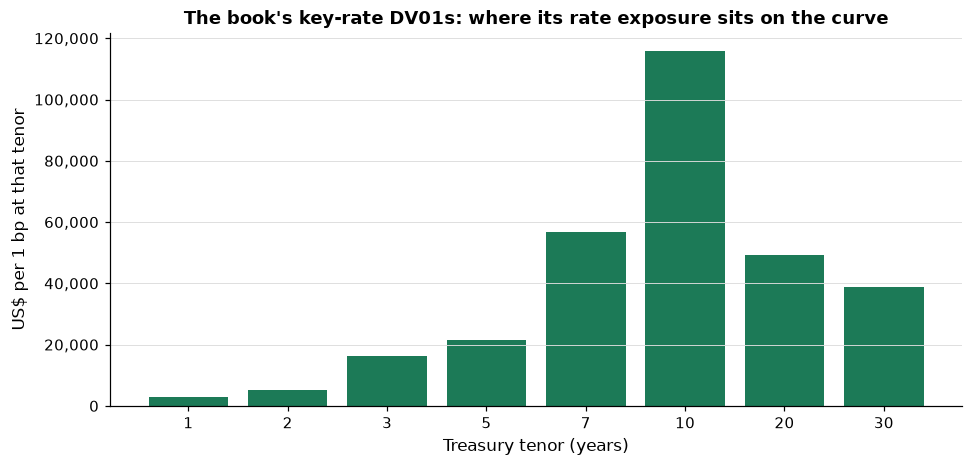

In [13]:
fig, ax = plt.subplots(figsize=(10, 4.4))
ax.bar([str(t) for t in tenors], key_rate_dv01, color=plotkit.GREEN)
ax.set_xlabel("Treasury tenor (years)")
ax.set_ylabel("US$ per 1 bp at that tenor")
ax.yaxis.set_major_formatter(lambda value, _: f"{value:,.0f}")
ax.set_title("The book's key-rate DV01s: where its rate exposure sits on the curve")
ax.grid(axis="x", visible=False)
plt.show()

* How to read it: each bar is what a 1 bp move at that one tenor, and nowhere else, costs the book. The bars add to US$306,996. The largest sits at 10 years, where most of the book's maturities fall. A bond maturing in 8 years splits its DV01 between the 7 and 10 year tenors, more to the 7. Two curves that move by the same amount on average but twist differently cost the book different amounts, which is why the P&L reads each bond's own tenor.

## 2.2 The Past Days and the Book's P&L

**How it works.** Historical simulation makes no assumption about the shape of the moves. It takes every past day's moves as one scenario and asks what that day would have done to today's book. Each scenario is a real day, so the fat tails, the skew, and the way rates and spreads moved together are all kept as they were, and nothing outside the days chosen can appear. The settings are which days (here the development years) and how a move is applied (first order: duration, spread duration, OAS). What comes out is one P&L per past day.

Q. Load the curve and the spreads, keep the development years, and turn levels into daily moves.

In [14]:
# the curve's tenors that every day of the file holds, renamed to years
TENOR_COLUMNS = {"1 Yr": 1, "2 Yr": 2, "3 Yr": 3, "5 Yr": 5, "7 Yr": 7, "10 Yr": 10, "20 Yr": 20, "30 Yr": 30}
curve = pd.read_csv("treasury_par_yields.csv", parse_dates=["date"], index_col="date")[list(TENOR_COLUMNS)]
spreads = pd.read_csv("course3_synthetic_spreads.csv", parse_dates=["date"], index_col="date")

# the development years only: the held-out years stay closed until the capstone
DEVELOPMENT_END = "2022-12-30"
development_curve = curve.loc[:DEVELOPMENT_END]
development_spreads = spreads.loc[:DEVELOPMENT_END]
print(f"held-out days left closed: {len(curve.loc[DEVELOPMENT_END:].iloc[1:]):,}")

# a day's move against the day before: Treasury changes in bp, spread changes relative to the level
rate_moves = (development_curve.diff() * 100).iloc[1:].rename(columns=TENOR_COLUMNS)
spread_moves = (development_spreads / development_spreads.shift(1) - 1).iloc[1:]
print(f"{len(rate_moves):,} daily moves, {rate_moves.index[0].date()} to {rate_moves.index[-1].date()}")
print(f"same dates in both files: {rate_moves.index.equals(spread_moves.index)}; missing values: {int(rate_moves.isna().sum().sum() + spread_moves.isna().sum().sum())}")

held-out days left closed: 939
2,000 daily moves, 2015-01-05 to 2022-12-30
same dates in both files: True; missing values: 0


* 2,000 days of moves. The 939 held-out days are counted and left alone.

Q. Add `historical_pnl` to `riskkit.py`. Read the docstring first.

In [15]:
%%writefile -a riskkit.py


import pandas as pd  # dated tables: the book's P&L by day
from scipy.stats import chi2  # the chi-squared distribution of Kupiec's test


def historical_pnl(book, rate_moves, spread_moves):
    """The book's P&L on each past day, had that day's rate and spread moves happened to today's book.

    For each bond and day: the rate move is the Treasury change at the bond's years to maturity, read off the curve
    by straight-line interpolation between the two nearest tenors (the first or last tenor beyond the ends); the
    spread move is the bond's OAS times the relative change in its spread index (the DTS approach). The P&L is
    minus market value x (duration x rate move + spread duration x spread move) / 10,000. First order only: no
    convexity, no carry, no roll down the curve.
    Inputs:
    - book: a DataFrame with one row per bond and the columns market_value (US$), duration, spread_duration, oas
      (bp), years_to_maturity, and spread_index (the name of a column of spread_moves).
    - rate_moves: a DataFrame of daily Treasury changes in bp, one row per date, one column per tenor in years.
    - spread_moves: a DataFrame of daily relative changes of each spread index (0.01 is 1 percent wider), on the
      same dates as rate_moves.
    Output: a DataFrame on those dates with the columns rates, spreads, and total, in US$.
    Raises ValueError for a missing book column, an unknown spread index, dates that differ, or a NaN in the moves.
    """
    needed = ["market_value", "duration", "spread_duration", "oas", "years_to_maturity", "spread_index"]
    missing = [name for name in needed if name not in book.columns]
    if missing:
        raise ValueError(f"book lacks the columns {missing}")
    unknown = sorted(set(book["spread_index"]) - set(spread_moves.columns))
    if unknown:
        raise ValueError(f"spread_moves has no column for the spread indexes {unknown}")
    if not rate_moves.index.equals(spread_moves.index):
        raise ValueError("rate_moves and spread_moves must be on the same dates")
    if rate_moves.isna().any().any() or spread_moves[list(set(book["spread_index"]))].isna().any().any():
        raise ValueError("the moves hold a NaN")
    tenors = np.asarray(rate_moves.columns, dtype=float)
    # interpolation is linear in the curve's values, so each bond's weight on each tenor is the curve 0 everywhere
    # but 1 at that tenor, read at the bond's maturity
    weights = np.column_stack([np.interp(book["years_to_maturity"], tenors, np.eye(len(tenors))[j])
                               for j in range(len(tenors))])
    bond_rate_moves = rate_moves.to_numpy() @ weights.T
    bond_spread_moves = spread_moves[book["spread_index"]].to_numpy() * book["oas"].to_numpy()
    rates = -(bond_rate_moves * (book["duration"] * book["market_value"]).to_numpy()).sum(axis=1) / 10_000
    spreads = -(bond_spread_moves * (book["spread_duration"] * book["market_value"]).to_numpy()).sum(axis=1) / 10_000
    return pd.DataFrame({"rates": rates, "spreads": spreads, "total": rates + spreads}, index=rate_moves.index)

Appending to riskkit.py


* Two imports come first: pandas, for the P&L table by date, and scipy's chi-squared distribution, which section 2.5 uses.
* The interpolation weights are section 2.1's: each bond reads the move at its own maturity, between the two nearest tenors.
* The docstring says what is left out: convexity, carry, and the roll down the curve. For one-day moves on a book like this one, first order is close; on a day with a very large move, convexity would soften the loss a little, and the P&L here leaves that out.

Q. Add its tests: one bond worked by hand, a maturity past the last tenor, and the refusals.

In [16]:
%%writefile -a test_riskkit.py


import pandas as pd


def _one_bond(years):
    return pd.DataFrame({"market_value": [1_000_000.0], "duration": [5.0], "spread_duration": [5.0], "oas": [100.0],
                         "years_to_maturity": [years], "spread_index": ["ig"]})


def test_historical_pnl_hand():
    # 4 years sits halfway between the 3 and 5 year tenors: a 15 bp move, and 10 percent of 100 bp is 10 bp
    dates = pd.to_datetime(["2020-01-02"])
    rates = pd.DataFrame({3.0: [10.0], 5.0: [20.0]}, index=dates)
    spreads = pd.DataFrame({"ig": [0.10]}, index=dates)
    pnl = riskkit.historical_pnl(_one_bond(4.0), rates, spreads)
    assert pnl.loc[dates[0], "rates"] == pytest.approx(-7_500.0, rel=1e-12)
    assert pnl.loc[dates[0], "spreads"] == pytest.approx(-5_000.0, rel=1e-12)
    assert pnl.loc[dates[0], "total"] == pytest.approx(-12_500.0, rel=1e-12)
    # beyond the last tenor the last tenor's move is used
    assert riskkit.historical_pnl(_one_bond(8.0), rates, spreads).loc[dates[0], "rates"] == pytest.approx(-10_000.0)


def test_historical_pnl_refuses():
    dates = pd.to_datetime(["2020-01-02", "2020-01-03"])
    rates = pd.DataFrame({3.0: [10.0, 1.0], 5.0: [20.0, 2.0]}, index=dates)
    with pytest.raises(ValueError, match="same dates"):
        riskkit.historical_pnl(_one_bond(4.0), rates, pd.DataFrame({"ig": [0.1]}, index=dates[:1]))
    with pytest.raises(ValueError, match="no column"):
        riskkit.historical_pnl(_one_bond(4.0), rates, pd.DataFrame({"hy": [0.1, 0.2]}, index=dates))
    with pytest.raises(ValueError, match="NaN"):
        riskkit.historical_pnl(_one_bond(4.0), rates.where(rates > 1), pd.DataFrame({"ig": [0.1, 0.2]}, index=dates))

Appending to test_riskkit.py


In [17]:
# the file changed, so reload before using the new function
importlib.reload(riskkit)
print(f"historical_pnl in riskkit: {hasattr(riskkit, 'historical_pnl')}")

historical_pnl in riskkit: True


In [18]:
# run the tests in the work folder with the kernel's own Python, in a fresh process
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "test_riskkit.py"],
                        cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

........                                                                 [100%]
8 passed in 1.67s



* `8 passed`: day 1's 6 and today's first two.

Q. Apply every development day to the book.

In [19]:
# the book of 2026-09-30 held fixed, each development day's moves applied to it
pnl = riskkit.historical_pnl(book, rate_moves, spread_moves)
print(pnl.describe().loc[["mean", "std", "min", "max"]].round(0).to_string())
print(f"correlation of the rate and spread parts: {pnl['rates'].corr(pnl['spreads']):.2f}")

# the rate part is the day's moves times the key-rate DV01s: the same number two ways
by_key_rates = -(rate_moves @ key_rate_dv01)
print(f"rate P&L equals the moves times the key-rate DV01s: {np.allclose(pnl['rates'], by_key_rates)}")

          rates    spreads      total
mean   -29536.0   -16318.0   -45854.0
std   1472807.0   885508.0  1726060.0
min  -8393918.0 -6952149.0 -8634065.0
max   9012077.0  4669515.0  8547153.0
correlation of the rate and spread parts: 0.01
rate P&L equals the moves times the key-rate DV01s: True


* A typical day moves the book by US$1.73m (one standard deviation): US$1.47m from rates and US$0.89m from spreads. The two parts are almost uncorrelated (0.01) over these years, so they partly offset: the total's standard deviation is well below the sum of the two parts'.
* The rate part equals the day's moves times the key-rate DV01s of section 2.1: the module and the hand calculation agree.

Q. Draw every day's P&L, with the worst five marked.

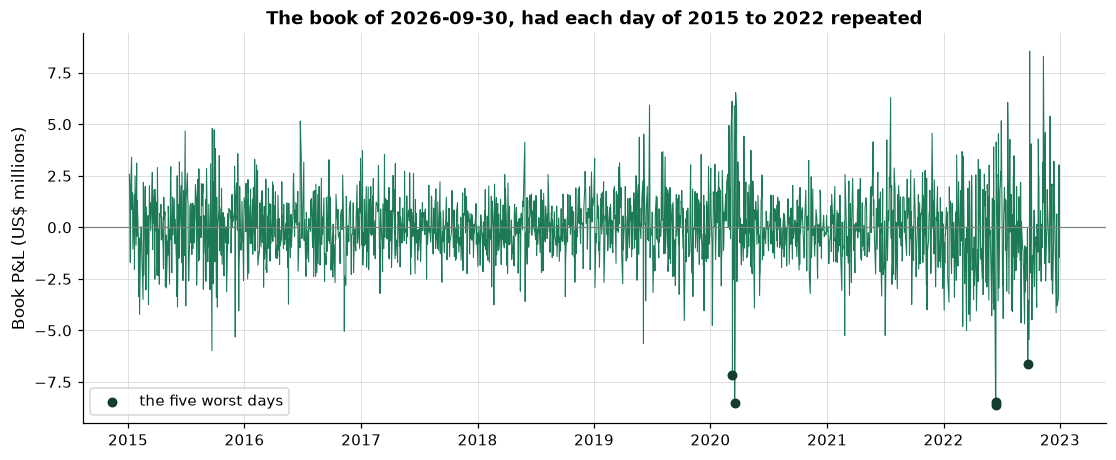

In [20]:
fig, ax = plt.subplots(figsize=(12, 4.6))
ax.plot(pnl.index, pnl["total"] / 1e6, color=plotkit.GREEN, linewidth=0.7)
worst_days = pnl["total"].nsmallest(5)
ax.scatter(worst_days.index, worst_days / 1e6, color=plotkit.GREEN_DARK, s=30, zorder=3, label="the five worst days")
ax.axhline(0, color=plotkit.GREY, linewidth=0.8)
ax.set_ylabel("Book P&L (US$ millions)")
ax.set_title("The book of 2026-09-30, had each day of 2015 to 2022 repeated")
ax.legend(loc="lower left")
plt.show()

* How to read it: one point per past day. Quiet years sit in a narrow band; 2020 and 2022 hold the five worst days, and the band is wider for months around them. Large days come in clusters, which matters for the backtest in section 2.5.

In [21]:
# the five worst days of the development years, with the two moves behind each
worst = pnl.nsmallest(5, "total").copy()
worst["10 Yr move (bp)"] = rate_moves.loc[worst.index, 10]
worst["HY spread move (percent)"] = spread_moves.loc[worst.index, "hy_spread_bp"] * 100
worst.index = worst.index.date
worst.index.name = "day"
worst.columns = ["rates (US$)", "spreads (US$)", "total (US$)", "10 Yr move (bp)", "HY spread move (percent)"]
print(worst.round(1).to_string())

            rates (US$)  spreads (US$)  total (US$)  10 Yr move (bp)  HY spread move (percent)
day                                                                                           
2022-06-14   -1681916.1     -6952148.5   -8634064.7              6.0                      15.3
2020-03-17   -8182034.3      -323922.5   -8505956.8             29.0                       1.0
2022-06-13   -8393918.4       -87817.8   -8481736.2             28.0                       0.5
2020-03-10   -6830216.5      -328680.6   -7158897.1             22.0                       0.6
2022-09-22   -5345683.2     -1285052.2   -6630735.4             19.0                       2.4


In [22]:
plotkit.styled(worst, [], "The five worst days of 2015 to 2022 for the book of 2026-09-30, with the 10 Yr and HY moves of "
               "each day", fmt="{:,.1f}")

,rates (US$),spreads (US$),total (US$),10 Yr move (bp),HY spread move (percent)
day,,,,,
2022-06-14,"-1,681,916.1","-6,952,148.5","-8,634,064.7",6.0,15.3
2020-03-17,"-8,182,034.3","-323,922.5","-8,505,956.8",29.0,1.0
2022-06-13,"-8,393,918.4","-87,817.8","-8,481,736.2",28.0,0.5
2020-03-10,"-6,830,216.5","-328,680.6","-7,158,897.1",22.0,0.6
2022-09-22,"-5,345,683.2","-1,285,052.2","-6,630,735.4",19.0,2.4


* The worst day, 2022-06-14, would have cost US$8.63m. The table says only what moved on each day; why the curve moved is not something these files record.

## 2.3 VaR and Expected Shortfall

**How it works.** **VaR** at 99 percent is the loss exceeded on 1 percent of the days: minus the 1st percentile of the P&L. It is one number, and it says nothing about how bad the days beyond it were. **Expected shortfall** (ES) answers that: the average loss on the days at or beyond the VaR. Both come from the same sorted P&L. The settings are the level (95, 97.5, or 99 percent) and how a percentile between two days is read (section 2.4). What comes out is two US$ losses, the second never below the first.

Q. Add `var_es` to `riskkit.py`, with its tests.

In [23]:
%%writefile -a riskkit.py


def var_es(pnl, level: float = 0.99) -> tuple[float, float]:
    """The VaR and the expected shortfall of a sample of P&L, both as positive US$ losses.

    VaR at level (for example 0.99) is minus the (1 - level) quantile of the P&L, with linear interpolation between
    the two nearest values: Excel's PERCENTILE.INC. Expected shortfall is minus the mean P&L on the days at or below
    that quantile: the average loss on the days the loss is at least the VaR, so it is never below the VaR.
    Inputs: pnl, a 1-D array of at least 2 values in US$, a gain positive, none of them NaN; level strictly between
    0.5 and 1.
    Output: (VaR, expected shortfall), in US$.
    Raises ValueError for fewer than 2 values, more than one dimension, a NaN, or a level outside (0.5, 1).
    """
    values = np.asarray(pnl, dtype=float)
    if values.ndim != 1 or len(values) < 2:
        raise ValueError("pnl must be a 1-D array of at least 2 values")
    if np.isnan(values).any():
        raise ValueError("pnl holds a NaN")
    if not 0.5 < level < 1:
        raise ValueError("level must be between 0.5 and 1")
    cutoff = float(np.quantile(values, 1 - level))
    return -cutoff, -float(values[values <= cutoff].mean())

Appending to riskkit.py


* The percentile is read with linear interpolation between the two nearest days, which is what Excel's `PERCENTILE.INC` does, so the two give the same VaR to the cent.
* A loss is reported as a positive number, as day 1 set out.

In [24]:
%%writefile -a test_riskkit.py


def test_var_es_hand():
    # losses of 1 to 100: the 5 percent quantile of the P&L sits 4.95 of the way from -100 to -99, so VaR 95.05;
    # the days at or below it lose 100, 99, 98, 97, and 96, an average of 98
    var, es = riskkit.var_es(-np.arange(1.0, 101.0), 0.95)
    assert var == pytest.approx(95.05, rel=1e-12)
    assert es == pytest.approx(98.0, rel=1e-12)


def test_var_es_shortfall_at_least_var():
    pnl = np.random.default_rng(42).standard_t(4, 5_000)
    for level in (0.95, 0.99):
        var, es = riskkit.var_es(pnl, level)
        assert es >= var > 0


def test_var_es_refuses():
    with pytest.raises(ValueError, match="NaN"):
        riskkit.var_es([1.0, float("nan"), -2.0])
    with pytest.raises(ValueError, match="between 0.5 and 1"):
        riskkit.var_es([1.0, -2.0, 3.0], 0.01)

Appending to test_riskkit.py


In [25]:
importlib.reload(riskkit)
print(f"var_es in riskkit: {hasattr(riskkit, 'var_es')}")

var_es in riskkit: True


In [26]:
# run the tests in the work folder with the kernel's own Python, in a fresh process
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "test_riskkit.py"],
                        cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

...........                                                              [100%]
11 passed in 1.70s



* `11 passed`. `test_var_es_hand` is worth reading: losses of 1 to 100 make every number checkable by hand.

Q. What are the VaR and expected shortfall of the book's development days at 95, 97.5, and 99 percent?

In [27]:
# VaR and expected shortfall of the development days, at three levels
var_table = pd.DataFrame(
    [riskkit.var_es(pnl["total"], level) for level in [0.95, 0.975, 0.99]],
    index=pd.Index(["95%", "97.5%", "99%"], name="level"), columns=["VaR (US$)", "expected shortfall (US$)"])
var_table["shortfall over VaR"] = var_table["expected shortfall (US$)"] / var_table["VaR (US$)"]
var_table["days beyond the VaR"] = [int((-pnl["total"] > v).sum()) for v in var_table["VaR (US$)"]]
print(var_table.round(2).to_string())

        VaR (US$)  expected shortfall (US$)  shortfall over VaR  days beyond the VaR
level                                                                               
95%    2816546.29                3899692.95                1.38                  100
97.5%  3524876.58                4671689.71                1.33                   50
99%    4490319.03                5790756.62                1.29                   20


In [28]:
plotkit.styled(var_table, ["expected shortfall (US$)"], "Historical VaR and expected shortfall of the book of 2026-09-30 "
               "over the 2,000 development days", fmt="{:,.2f}")

,VaR (US$),expected shortfall (US$),shortfall over VaR,days beyond the VaR
level,,,,
95%,"2,816,546.29","3,899,692.95",1.38,100
97.5%,"3,524,876.58","4,671,689.71",1.33,50
99%,"4,490,319.03","5,790,756.62",1.29,20


* Had the daily moves of 2015 to 2022 repeated, with the book of 2026-09-30 held fixed, the 99th percentile one-day loss was US$4.49m, and the average loss on the days beyond it US$5.79m.
* 20 of the 2,000 days lost more than the 99 percent VaR: 1 percent, by construction. The VaR is a percentile of these days, so it is beaten on exactly the share of them it says.

Q. Draw the P&L's distribution and its left tail.

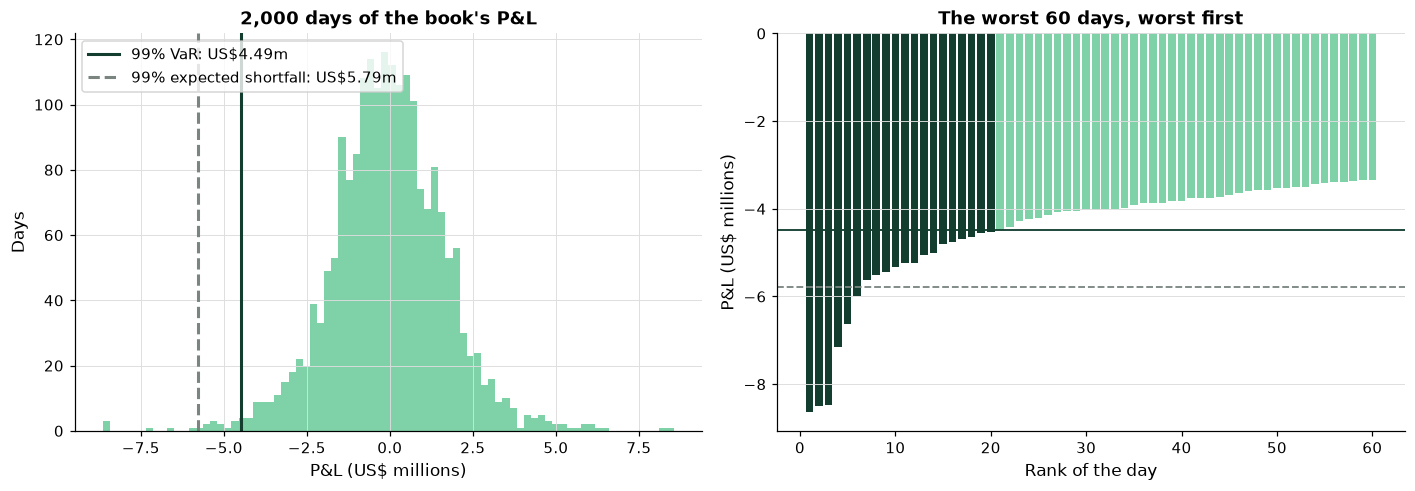

In [29]:
var_99, es_99 = riskkit.var_es(pnl["total"], 0.99)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
values = pnl["total"] / 1e6
axes[0].hist(values, bins=80, color=plotkit.GREEN_LIGHT)
axes[0].axvline(-var_99 / 1e6, color=plotkit.GREEN_DARK, linewidth=2, label=f"99% VaR: US${var_99 / 1e6:.2f}m")
axes[0].axvline(-es_99 / 1e6, color=plotkit.GREY, linewidth=2, linestyle="--", label=f"99% expected shortfall: US${es_99 / 1e6:.2f}m")
axes[0].set_title("2,000 days of the book's P&L")
axes[0].set_xlabel("P&L (US$ millions)")
axes[0].set_ylabel("Days")
axes[0].legend(loc="upper left")
# the left tail only: the worst 60 days, each a bar, the 20 beyond the VaR dark
tail = np.sort(pnl["total"].to_numpy())[:60] / 1e6
axes[1].bar(np.arange(1, 61), tail, color=[plotkit.GREEN_DARK if v < -var_99 / 1e6 else plotkit.GREEN_LIGHT for v in tail])
axes[1].axhline(-var_99 / 1e6, color=plotkit.GREEN_DARK, linewidth=1.2)
axes[1].axhline(-es_99 / 1e6, color=plotkit.GREY, linewidth=1.2, linestyle="--")
axes[1].set_title("The worst 60 days, worst first")
axes[1].set_xlabel("Rank of the day")
axes[1].set_ylabel("P&L (US$ millions)")
axes[1].grid(axis="x", visible=False)
fig.tight_layout()
plt.show()

* How to read it: on the left the whole distribution, with the VaR and the expected shortfall marked in its left tail. On the right the worst 60 days, one bar each. The dark bars are the days beyond the VaR; their average is the dashed line. The worst few days are far below the VaR: a VaR alone hides them, the expected shortfall does not.

## 2.4 Three Models, and Every Setting

**How it works.** Historical simulation is one model of the next day: "one of these 2,000 days". Two others are common. The **normal model** assumes the P&L is normal with the sample's mean and standard deviation, and reads the VaR off the formula: the mean plus 2.326 standard deviations down at 99 percent. A **Student's t Monte Carlo** fits a t distribution to the days, whose degrees of freedom set how fat its tails are (day 1, section 1.4), and simulates from it. The settings are the model, its fitted parameters, and the seed of the simulation. What comes out is three VaRs for the same book and the same days, and the gap between them is a measure of how much the answer depends on the model.

Q. Compute the VaR and expected shortfall of the normal model and of a t fitted to the days, beside the historical numbers.

In [30]:
from scipy.stats import norm, t as t_dist

total = pnl["total"]
mean, sd = float(total.mean()), float(total.std())

# Student's t fitted by maximum likelihood to the development days: degrees of freedom, centre, and scale
df_t, loc_t, scale_t = t_dist.fit(total)
# 200,000 simulated days from the fitted t
rng = np.random.default_rng(SEED)
t_days = loc_t + scale_t * rng.standard_t(df_t, 200_000)

rows = []
for level in [0.95, 0.99]:
    z = norm.ppf(1 - level)
    historical = riskkit.var_es(total, level)
    # the normal model: the VaR is the mean plus z standard deviations; its shortfall has a closed form
    normal = (-(mean + z * sd), -(mean - sd * norm.pdf(z) / (1 - level)))
    student = riskkit.var_es(t_days, level)
    for model, (var, es) in [("historical", historical), ("normal", normal), (f"Student's t, df {df_t:.1f}, Monte Carlo", student)]:
        rows.append({"level": f"{level:.0%}", "model": model, "VaR (US$)": var, "expected shortfall (US$)": es})
models = pd.DataFrame(rows).set_index(["level", "model"])
print(models.round(0).to_string())

                                        VaR (US$)  expected shortfall (US$)
level model                                                                
95%   historical                        2816546.0                 3899693.0
      normal                            2884970.0                 3606220.0
      Student's t, df 6.1, Monte Carlo  2756407.0                 3825621.0
99%   historical                        4490319.0                 5790757.0
      normal                            4061269.0                 4646173.0
      Student's t, df 6.1, Monte Carlo  4450813.0                 5651124.0


In [31]:
plotkit.styled(models, [], "Three models of the same 2,000 days: historical, normal, and a fitted Student's t simulated "
               "200,000 times", fmt="{:,.0f}")

<styled table: Three models of the same 2,000 days: historical, normal, and a fitted Student's t simulated 200,000 times>

* At 95 percent the normal model is close to the history (US$2.88m against US$2.82m). At 99 percent it says US$4.06m against the history's US$4.49m: too small, because the book's worst days are more extreme than a normal distribution allows. Its expected shortfall, US$4.65m, misses by more.
* The fitted t has 6.1 degrees of freedom: tails clearly fatter than the normal's. Its 99 percent VaR, US$4.45m, and its shortfall, US$5.65m, sit much closer to the history.

Q. How much more often than the normal says do the large days happen? Count the days beyond 2, 3, and 4 standard deviations.

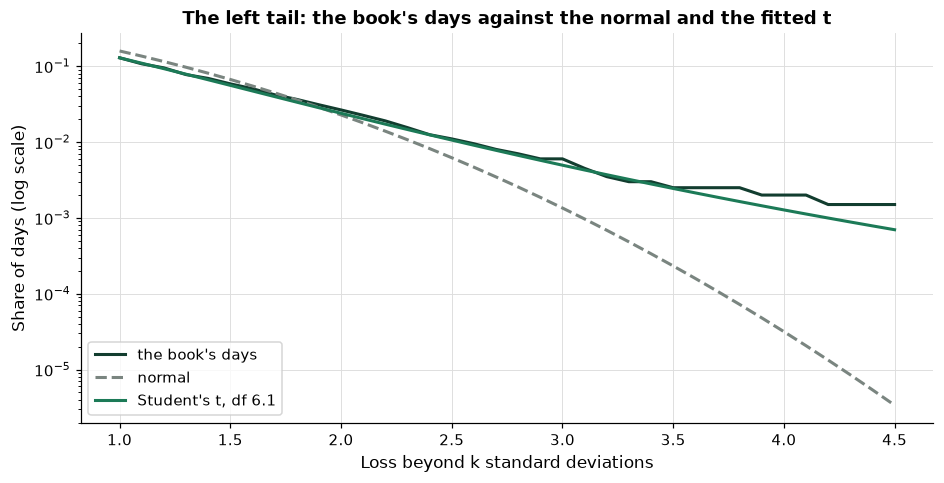

In [32]:
standardised = (total - mean) / sd
fig, ax = plt.subplots(figsize=(10, 4.6))
# up to 4.5 standard deviations: past the worst day the share is 0, which a log scale cannot draw
k = np.linspace(1, 4.5, 36)
ax.plot(k, [np.mean(standardised < -x) for x in k], color=plotkit.GREEN_DARK, linewidth=2, label="the book's days")
ax.plot(k, norm.cdf(-k), color=plotkit.GREY, linestyle="--", linewidth=2, label="normal")
# the fitted t, in the same standard deviations
ax.plot(k, t_dist.cdf(mean - k * sd, df_t, loc_t, scale_t), color=plotkit.GREEN, linewidth=2, label=f"Student's t, df {df_t:.1f}")
ax.set_yscale("log")
ax.set_xlabel("Loss beyond k standard deviations")
ax.set_ylabel("Share of days (log scale)")
ax.set_title("The left tail: the book's days against the normal and the fitted t")
ax.legend(loc="lower left")
plt.show()

* How to read it: the y axis is logarithmic, so each step down is ten times rarer. Out to 2 standard deviations the three lines are close; by 3 and 4 the book's days run far above the normal, and the t follows them. The 99 percent VaR sits near 2.3 standard deviations, at the start of the gap: the further into the tail the question, the more the normal model understates.

Q. Read every setting of today's VaR, and sweep the one the module fixes: how a percentile between two days is read.

In [33]:
# np.quantile's method setting: how a quantile between two days is read; the VaR at 99 percent under each
methods = {"linear": "PERCENTILE.INC", "weibull": "PERCENTILE.EXC", "lower": "", "higher": "", "nearest": "",
           "midpoint": ""}
method_table = pd.DataFrame({
    "VaR at 99% (US$)": {m: -float(np.quantile(pnl["total"], 0.01, method=m)) for m in methods},
    "Excel's function": methods,
})
method_table["gap to linear (US$)"] = method_table["VaR at 99% (US$)"] - method_table.loc["linear", "VaR at 99% (US$)"]
method_table.index.name = "method"
print(method_table.round(0).to_string())

          VaR at 99% (US$) Excel's function  gap to linear (US$)
method                                                          
linear           4490319.0   PERCENTILE.INC                  0.0
weibull          4523251.0   PERCENTILE.EXC              32932.0
lower            4523587.0                               33268.0
higher           4489983.0                                -336.0
nearest          4489983.0                                -336.0
midpoint         4506785.0                               16466.0


In [34]:
settings = pd.DataFrame([
    ("level", "0.95, 0.975, 0.99", "how far into the tail: 1 day in 20, 40, or 100", "var_es(pnl, level)"),
    ("method", "linear (PERCENTILE.INC)", "how a percentile between two days is read", "np.quantile(..., method=)"),
    ("window", "all 2,000 days; 250, 500, 1,000 in the backtest", "how many past days make one VaR", "rolling(window)"),
    ("horizon", "1 day", "the holding period the loss is measured over", "sums of daily P&L, section 2.6"),
    ("model", "historical, normal, Student's t", "what shape the moves are given", "this section"),
], columns=["setting", "today's choice", "what it controls", "where it is set"]).set_index("setting")
plotkit.styled(settings, [], "The settings of a VaR: today's choice for each and where it is set")

,today's choice,what it controls,where it is set
setting,,,
level,"0.95, 0.975, 0.99","how far into the tail: 1 day in 20, 40, or 100","var_es(pnl, level)"
method,linear (PERCENTILE.INC),how a percentile between two days is read,"np.quantile(..., method=)"
window,"all 2,000 days; 250, 500, 1,000 in the backtest",how many past days make one VaR,rolling(window)
horizon,1 day,the holding period the loss is measured over,"sums of daily P&L, section 2.6"
model,"historical, normal, Student's t",what shape the moves are given,this section


* Every percentile method gives a VaR within US$33,604 of the others: with 2,000 days, the 1st percentile sits between the 20th and 21st worst days, and the methods differ only in how they read between those two. With 250 days the gap would be much larger, because the 1st percentile then sits between the 2nd and 3rd worst. `linear` is Excel's `PERCENTILE.INC`; `weibull` is `PERCENTILE.EXC`.

## 2.5 The Backtest

**How it works.** A VaR is a claim that can be checked: at 99 percent, a loss beyond it should come on about 1 day in 100. The backtest walks forward through time. On each day it computes the VaR from the 500 days before that day, never from the day itself, then compares the day's loss with it. A day whose loss is larger is an **exception**. If the VaR is right, the exceptions are like independent coin flips with a 1 percent chance, and their count can be tested. **Kupiec's proportion-of-failures test** (1995) compares the count with that chance through a likelihood ratio, close to a chi-squared with 1 degree of freedom. The settings are the window, the level, and the days tested. What comes out is the count, the count a correct VaR would give, and a p-value: a small p-value says the count is hard to square with the level, too many exceptions or too few.

Q. Compute each day's VaR from the 500 days before it, and count the exceptions.

In [35]:
WINDOW, LEVEL = 500, 0.99
total = pnl["total"]
# each day's VaR from the 500 days before it, never from the day itself: shift(1) moves each window's answer one day on
rolling_var = -total.rolling(WINDOW).quantile(1 - LEVEL).shift(1)
tested = rolling_var.dropna().index
# an exception is a day whose loss is larger than that day's VaR
exceptions = -total[tested] > rolling_var[tested]
n_tested, n_exceptions = len(tested), int(exceptions.sum())
print(f"days tested: {n_tested:,}, {tested[0].date()} to {tested[-1].date()}")
print(f"exceptions: {n_exceptions}, against {n_tested * (1 - LEVEL):.0f} for a correct 99 percent VaR")

days tested: 1,500, 2017-01-03 to 2022-12-30
exceptions: 28, against 15 for a correct 99 percent VaR


* 28 exceptions in 1,500 days, against 15 for a correct 99 percent VaR. The first 500 days only feed the window, so the test starts on 2017-01-03.

Q. Add `kupiec_pof` to `riskkit.py`, with its tests.

In [36]:
%%writefile -a riskkit.py


def kupiec_pof(exceptions: int, n: int, level: float) -> tuple[float, float]:
    """Kupiec's proportion-of-failures test: is the count of VaR exceptions in line with the VaR's level?

    Under a correct VaR each of n days is an exception with chance p = 1 - level, independently. The statistic is
    the likelihood ratio LR = -2 ln[(1 - p)^(n - x) p^x] + 2 ln[(1 - x/n)^(n - x) (x/n)^x] for x exceptions, which
    is close to a chi-squared with 1 degree of freedom when the VaR is right.
    Inputs: exceptions, a whole number from 0 to n; n, the number of days tested, above 0; level strictly between
    0 and 1.
    Output: (LR, p-value). A small p-value says the count is hard to square with the level: too many exceptions,
    or too few.
    Raises ValueError for a count outside 0 to n, an n that is not above 0, or a level outside (0, 1).
    """
    if n <= 0 or not 0 <= exceptions <= n:
        raise ValueError("exceptions must be between 0 and n, and n above 0")
    if not 0 < level < 1:
        raise ValueError("level must be between 0 and 1")
    p, x = 1 - level, exceptions
    observed = x / n

    def log_likelihood(q: float) -> float:
        # x ln q + (n - x) ln(1 - q), with 0 ln 0 taken as 0
        return (x * math.log(q) if x else 0.0) + ((n - x) * math.log(1 - q) if n - x else 0.0)

    lr = max(0.0, -2 * (log_likelihood(p) - log_likelihood(observed)))
    return lr, float(chi2.sf(lr, 1))

Appending to riskkit.py


* The docstring writes the statistic out. Its two terms are the chance of the count under the VaR's level and under the observed share; the larger their gap, the larger the statistic.
* A count of 0 is allowed: the code takes 0 ln 0 as 0, the usual limit, rather than failing.

In [37]:
%%writefile -a test_riskkit.py


def test_kupiec_pof_hand():
    # exactly the expected count: the statistic is 0 and the p-value 1
    assert riskkit.kupiec_pof(10, 1_000, 0.99) == pytest.approx((0.0, 1.0))
    # 5 exceptions in 250 days at 99 percent, against the formula written out
    x, n, p = 5, 250, 0.01
    lr = -2 * ((n - x) * math.log(1 - p) + x * math.log(p) - (n - x) * math.log(1 - x / n) - x * math.log(x / n))
    assert riskkit.kupiec_pof(x, n, 0.99)[0] == pytest.approx(lr, rel=1e-12)
    # no exception at all is too few for a long sample
    assert riskkit.kupiec_pof(0, 2_000, 0.99)[1] < 0.01


def test_kupiec_pof_refuses():
    with pytest.raises(ValueError, match="between 0 and n"):
        riskkit.kupiec_pof(11, 10, 0.99)

Appending to test_riskkit.py


In [38]:
importlib.reload(riskkit)
print(f"kupiec_pof in riskkit: {hasattr(riskkit, 'kupiec_pof')}")

kupiec_pof in riskkit: True


In [39]:
# run the tests in the work folder with the kernel's own Python, in a fresh process
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "test_riskkit.py"],
                        cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

.............                                                            [100%]
13 passed in 1.69s



* `13 passed`: day 1's 6 and today's 7.

Q. Is 28 in 1,500 in line with a 99 percent VaR? And year by year?

In [40]:
lr, p_value = riskkit.kupiec_pof(n_exceptions, n_tested, LEVEL)
print(f"Kupiec's test: LR {lr:.2f}, p-value {p_value:.4f}")
# the same test on the exceptions of each calendar year, about 250 days each
by_year = pd.DataFrame({"days tested": exceptions.groupby(exceptions.index.year).size(),
                        "exceptions": exceptions.groupby(exceptions.index.year).sum()})
by_year["expected"] = by_year["days tested"] * (1 - LEVEL)
by_year["p-value"] = [riskkit.kupiec_pof(int(x), int(n), LEVEL)[1] for n, x in zip(by_year["days tested"], by_year["exceptions"])]
by_year.index.name = "year"
print(by_year.round(4).to_string())

Kupiec's test: LR 9.07, p-value 0.0026
      days tested  exceptions  expected  p-value
year                                            
2017          250           0      2.50   0.0250
2018          249           5      2.49   0.1597
2019          250           8      2.50   0.0054
2020          251           4      2.51   0.3843
2021          251           2      2.51   0.7373
2022          249           9      2.49   0.0013


* Over all 1,500 days, the p-value is 0.0026: a correct 99 percent VaR would give 28 or more exceptions very rarely. This VaR, built from the 500 days before each day, was beaten too often.
* Year by year, 2022 had 9 exceptions and 2017 had none. None is a failure too: its p-value is 0.0250, because a correct VaR beaten on no day of a year would be a VaR set too high. A window of past days is slow: after a calm stretch it holds few large days, so when the moves grow the VaR is too small for months.

Q. Draw each day's loss against that day's VaR, with the exceptions marked.

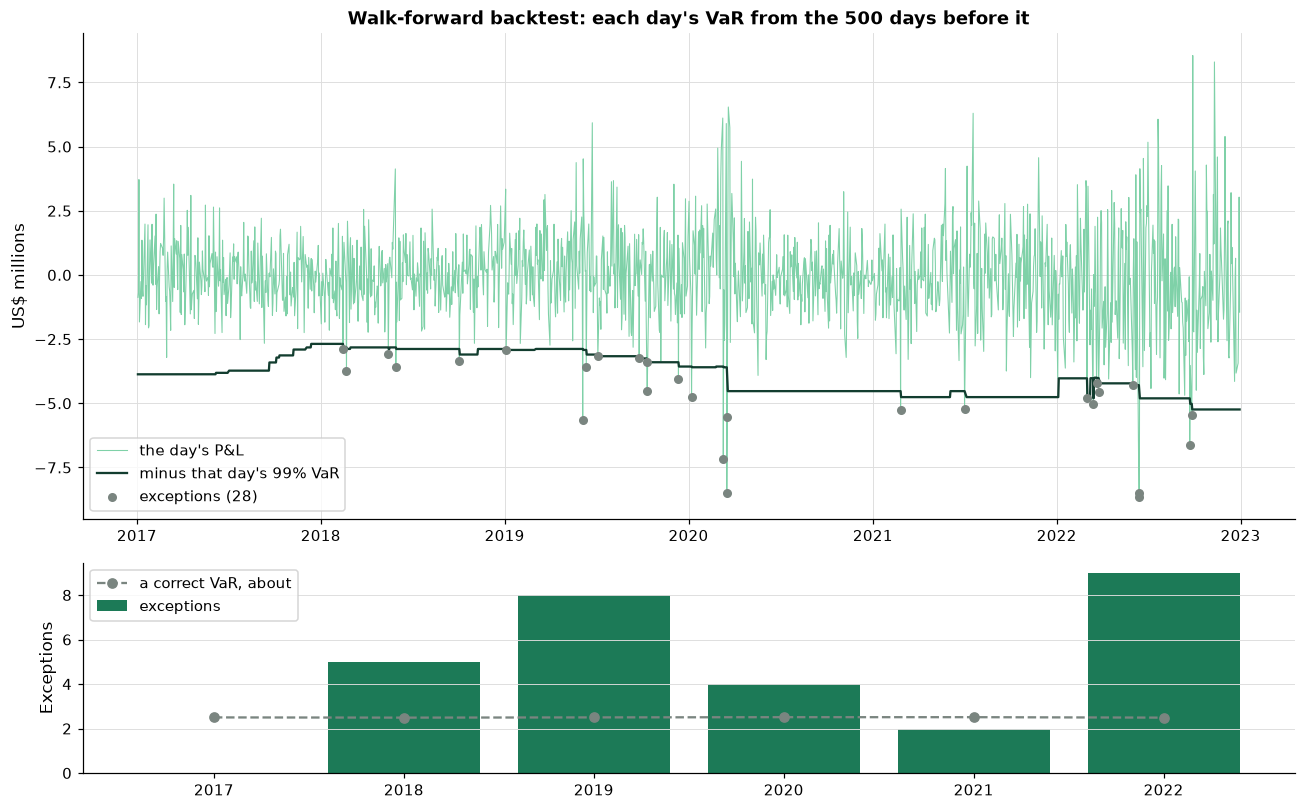

In [41]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7.5), gridspec_kw={"height_ratios": [3, 1.3]})
axes[0].plot(tested, total[tested] / 1e6, color=plotkit.GREEN_LIGHT, linewidth=0.7, label="the day's P&L")
axes[0].plot(tested, -rolling_var[tested] / 1e6, color=plotkit.GREEN_DARK, linewidth=1.5, label="minus that day's 99% VaR")
hit = tested[exceptions.to_numpy()]
axes[0].scatter(hit, total[hit] / 1e6, color=plotkit.GREY, s=24, zorder=3, label=f"exceptions ({len(hit)})")
axes[0].set_ylabel("US$ millions")
axes[0].set_title("Walk-forward backtest: each day's VaR from the 500 days before it")
axes[0].legend(loc="lower left")
axes[1].bar(by_year.index.astype(str), by_year["exceptions"], color=plotkit.GREEN, label="exceptions")
axes[1].plot(by_year.index.astype(str), by_year["expected"], color=plotkit.GREY, marker="o", linestyle="--",
             label="a correct VaR, about")
axes[1].set_ylabel("Exceptions")
axes[1].legend(loc="upper left")
axes[1].grid(axis="x", visible=False)
fig.tight_layout()
plt.show()

* How to read it: in the top panel the dark line is the loss each day's VaR allowed; a grey dot is a day that lost more. The line moves slowly, because each day only one day enters the 500-day window and one leaves. The exceptions bunch where the moves grew after a quiet stretch. The bottom panel counts them by year against about 2.5 a year for a correct VaR. Exceptions in clusters break the coin-flip assumption too, which Kupiec's test does not look at: it counts, and does not ask when.

Q. Sweep the window and the level. Is any of them in line?

In [42]:
# every window and level: the exceptions against the count a correct VaR would give, and Kupiec's p-value
sweep_rows = []
for window in [250, 500, 1_000]:
    var_w = {level: -total.rolling(window).quantile(1 - level).shift(1) for level in [0.95, 0.99]}
    for level, v in var_w.items():
        days = v.dropna().index
        count = int((-total[days] > v[days]).sum())
        sweep_rows.append({"window (days)": window, "level": f"{level:.0%}", "days tested": len(days),
                           "exceptions": count, "expected": len(days) * (1 - level),
                           "p-value": riskkit.kupiec_pof(count, len(days), level)[1]})
sweep = pd.DataFrame(sweep_rows).set_index(["window (days)", "level"])
print(sweep.round(4).to_string())

                     days tested  exceptions  expected  p-value
window (days) level                                            
250           95%           1750         103      87.5   0.0978
              99%           1750          29      17.5   0.0116
500           95%           1500         103      75.0   0.0016
              99%           1500          28      15.0   0.0026
1000          95%           1000          99      50.0   0.0000
              99%           1000          22      10.0   0.0010


In [43]:
plotkit.styled(sweep, ["p-value"], "Walk-forward backtest of the book's VaR over the development years: every window and "
               "level", fmt="{:,.4f}")

<styled table: Walk-forward backtest of the book's VaR over the development years: every window and level>

* Every row is beaten more often than it should be: from 1.2 to 2.2 times the count a correct VaR would give.
* Mind what each row tests. A 1,000-day window has no VaR until 2019-01-03, so its tested days are the later ones, which held most of the large moves; the rows are not tested on the same days, and a fair comparison of windows would test them on the same days. A longer window holds more large days but reacts more slowly; a shorter one reacts faster but each VaR rests on fewer days. Neither fixes the problem here, which is that the size of the moves changed over the years. Course 5B's GARCH (day 7) is one published answer to that.

## 2.6 Longer Horizons

**How it works.** A one-day VaR is turned into a 10-day one in two ways. The **square-root-of-time rule** multiplies it by the square root of 10, which is right when days are independent and alike. Or the P&L is summed over 10 days and the VaR read off the sums: **overlapping** sums use every 10-day stretch (1 to 10, 2 to 11, and so on), which gives many samples that share 9 days with their neighbours; **separate** blocks share none, and there are only a tenth as many. The setting is the horizon and how it is built. What comes out is a 10-day VaR.

Q. Compute the 10-day VaR at 99 percent all three ways.

In [44]:
# a 10-day VaR three ways: the 1-day VaR times the square root of 10, overlapping 10-day sums, and separate 10-day blocks
one_day = riskkit.var_es(total, 0.99)[0]
overlapping = total.rolling(10).sum().dropna()
blocks = total.groupby(np.arange(len(total)) // 10).sum()
horizon = pd.DataFrame({
    "10-day VaR at 99% (US$)": [one_day * np.sqrt(10), riskkit.var_es(overlapping, 0.99)[0], riskkit.var_es(blocks, 0.99)[0]],
    "samples": [len(total), len(overlapping), len(blocks)],
}, index=pd.Index(["1-day VaR x square root of 10", "overlapping 10-day sums", "separate 10-day blocks"], name="method"))
print(horizon.round(0).to_string())

                               10-day VaR at 99% (US$)  samples
method                                                         
1-day VaR x square root of 10               14199636.0     2000
overlapping 10-day sums                     15079802.0     1991
separate 10-day blocks                      13896841.0      200


In [45]:
plotkit.styled(horizon, ["10-day VaR at 99% (US$)"], "The book's 10-day VaR at 99 percent, three ways, over the "
               "development years", fmt="{:,.0f}")

,10-day VaR at 99% (US$),samples
method,,
1-day VaR x square root of 10,"14,199,636","2,000"
overlapping 10-day sums,"15,079,802","1,991"
separate 10-day blocks,"13,896,841",200


* The square-root rule gives US$14.20m, the overlapping sums US$15.08m, and the 200 separate blocks US$13.90m. The overlapping number is higher than the rule: large days came in runs over these years, so ten days added up to more than ten independent days would. The separate blocks rest on 200 samples, so their 1st percentile sits between the 2nd and 3rd worst block, and moves a lot with which days begin a block.

## A Story: RiskMetrics Makes VaR a Public Method

In October 1994, J.P. Morgan launched RiskMetrics: a published method for measuring market risk, with daily data sets of volatilities and correlations to feed it. The fourth edition of its Technical Document, dated New York, December 17, 1996, says the firm made the methodology and the data available "to establish a benchmark for market risk measurement", and that "all publications and daily data sets are available free of charge" on its web site. In its standard form a VaR was 1.65 standard deviations, a loss not exceeded 95 percent of the time. The document already describes historical simulation as making "no explicit assumptions about the distribution of asset returns", with lookback periods that "typically range from 6 months to 2 years". On its first page it reminds readers that "no amount of sophisticated analytics will replace experience and professional judgment in managing risks."

The point for a desk: today's three models and today's backtest are the questions practitioners were already asking in public thirty years ago. A VaR is a percentile of a chosen past, and only a backtest says whether that past was a fair guide.

Sources: J.P. Morgan and Reuters, *RiskMetrics Technical Document*, Fourth Edition, New York, December 17, 1996: the cover page, the preface (page iii), and pages 6 and 27; MSCI's page for the document, https://www.msci.com/research-and-insights/paper/1996-riskmetrics-technical-document . The test of section 2.5: Paul H. Kupiec, "Techniques for Verifying the Accuracy of Risk Measurement Models", Finance and Economics Discussion Series 95-24, Board of Governors of the Federal Reserve System, 1995, https://fedinprint.org/item/fedgfe/34596/original ; published in *The Journal of Derivatives* 3 (2), 1995, pages 73 to 84.

## Excel Side by Side

Excel computes a historical VaR with one function and its shortfall with another: `PERCENTILE.INC` reads the percentile, and `AVERAGEIF` averages the days beyond it. Every formula below was typed into Excel by script (Excel 16.0 build 20430, 2026-10-24). The check pasted the 2,000 days of the book's P&L of section 2.2 into B2:B2001 (the rate part in C, the spread part in D), and the 1,500 tested days of section 2.5 with their VaR into F2:G1501.

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Excel returned</th></tr>
<tr><td align="left">99% VaR</td><td align="left"><code>riskkit.var_es(pnl["total"], 0.99)[0]</code></td><td align="left"><code>=-PERCENTILE.INC(B2:B2001,0.01)</code></td><td align="left">US$4,490,319</td></tr>
<tr><td align="left">99% expected shortfall</td><td align="left"><code>riskkit.var_es(pnl["total"], 0.99)[1]</code></td><td align="left"><code>=-AVERAGEIF(B2:B2001,"&lt;="&amp;PERCENTILE.INC(B2:B2001,0.01))</code></td><td align="left">US$5,790,757</td></tr>
<tr><td align="left">95% VaR and shortfall</td><td align="left"><code>riskkit.var_es(pnl["total"], 0.95)</code></td><td align="left"><code>=-PERCENTILE.INC(B2:B2001,0.05)</code> and <code>=-AVERAGEIF(B2:B2001,"&lt;="&amp;PERCENTILE.INC(B2:B2001,0.05))</code></td><td align="left">US$2,816,546 and US$3,899,693</td></tr>
<tr><td align="left">The normal model at 99%</td><td align="left"><code>-(mean + norm.ppf(0.01) * sd)</code></td><td align="left"><code>=-(AVERAGE(B2:B2001)+NORM.S.INV(0.01)*STDEV.S(B2:B2001))</code></td><td align="left">US$4,061,269</td></tr>
<tr><td align="left">The other percentile method</td><td align="left"><code>np.quantile(..., method="weibull")</code></td><td align="left"><code>=-PERCENTILE.EXC(B2:B2001,0.01)</code></td><td align="left">US$4,523,251</td></tr>
<tr><td align="left">Exceptions in the backtest</td><td align="left"><code>(-total[tested] &gt; rolling_var[tested]).sum()</code></td><td align="left"><code>=SUMPRODUCT(--(-F2:F1501&gt;G2:G1501))</code></td><td align="left">28</td></tr>
<tr><td align="left">Kupiec's statistic</td><td align="left"><code>riskkit.kupiec_pof(x, n, 0.99)[0]</code></td><td align="left"><code>=-2*((K2-K1)*LN(1-K4)+K1*LN(K4)-(K2-K1)*LN(1-K1/K2)-K1*LN(K1/K2))</code></td><td align="left">9.0668</td></tr>
<tr><td align="left">Its p-value</td><td align="left"><code>riskkit.kupiec_pof(x, n, 0.99)[1]</code></td><td align="left"><code>=CHISQ.DIST.RT(K3,1)</code></td><td align="left">0.002603</td></tr>
<tr><td align="left">The square-root-of-time 10-day VaR</td><td align="left"><code>one_day * np.sqrt(10)</code></td><td align="left"><code>=SQRT(10)*E1</code></td><td align="left">US$14,199,636</td></tr>
</table>
<br clear="left">

**Percentiles.** `PERCENTILE.INC(B2:B2001,0.01)` is the 1st percentile of the P&L, read by straight line between the two nearest days: the VaR is minus it. `PERCENTILE.EXC` reads the percentile a slightly different way, and is numpy's `weibull` method; with 2,000 days the two differ by US$32,932. `QUARTILE.INC` and `MEDIAN` are the same function at other levels.

**The shortfall.** `AVERAGEIF(B2:B2001,"<="&PERCENTILE.INC(B2:B2001,0.01))` averages the days at or below that percentile; minus it is the expected shortfall. The criterion is text joined to a number with `&`, the usual way to put a computed threshold into `AVERAGEIF` or `COUNTIF`.

**The test.** The exception count is a `SUMPRODUCT` over two columns, and Kupiec's statistic is the docstring's formula typed with `LN`; `CHISQ.DIST.RT` turns it into the p-value. A rolling window in Excel is a `PERCENTILE.INC` over a range that moves down one row per row, `PERCENTILE.INC(B2:B501,0.01)` beside day 501 and so on, which the check did not need because it pasted Python's column.

In [46]:
# Excel's results, from the course's Excel check, beside Python's
var_99, es_99 = riskkit.var_es(total, 0.99)
excel_side = pd.DataFrame({
    "Excel": [4490319.033602597, 5790756.620447682, 4061269.372166947, 9.066779573238932, 0.00260295087585966],
    "Python": [var_99, es_99, -(mean + norm.ppf(0.01) * sd), lr, p_value],
}, index=pd.Index(["99% VaR (US$)", "99% expected shortfall (US$)", "99% VaR, normal model (US$)",
                    "Kupiec's statistic", "Kupiec's p-value"], name="Check"))
excel_side["equal within 1e-6"] = (excel_side["Excel"] - excel_side["Python"]).abs() < 1e-6
plotkit.styled(excel_side, [], "Excel beside Python on the book's 2,000 development days", fmt="{:,.6f}")

,Excel,Python,equal within 1e-6
Check,,,
99% VaR (US$),"4,490,319.033603","4,490,319.033603",True
99% expected shortfall (US$),"5,790,756.620448","5,790,756.620448",True
"99% VaR, normal model (US$)","4,061,269.372167","4,061,269.372167",True
Kupiec's statistic,9.066780,9.066780,True
Kupiec's p-value,0.002603,0.002603,True


* Every value is equal within 1e-6, and the exception count is the same.

## Save the Day with Git

Today's Git step searches what Git tracks. `git grep` looks only in tracked files, so it answers "which functions does the committed module hold?" without opening anything.

Q. Start a repository in the work folder, and tell Git which files never to track.

In [47]:
# stop here, with the steps to install it, if Git is not on this machine
if shutil.which("git") is None:
    raise RuntimeError("Git is not installed. Install Git for Windows from https://git-scm.com/downloads "
                       "(or run  winget install --id Git.Git  where your firm allows it), restart VS Code, "
                       "and run this cell again. Colab has Git already.")

# -C "{work}" points every Git command at the work folder, whatever folder the notebook is in
!git -C "{work}" --version
# make the work folder a repository
!git -C "{work}" init -q -b main
# settings for this repository only: a course name, a reserved example email, line endings left as they are,
# and no commit signing, so a signing setup on your machine does not ask for a key here
!git -C "{work}" config user.name "Course Student"
!git -C "{work}" config user.email "student@example.com"
!git -C "{work}" config core.autocrlf false
!git -C "{work}" config commit.gpgsign false

git version 2.50.1.windows.1


Q. Is Git working in the work folder, and only there?

In [48]:
# the guard: Git must report the work folder as the top of this repository, or the notebook stops
top = subprocess.run(["git", "-C", str(work), "rev-parse", "--show-toplevel"],
                     capture_output=True, text=True, check=True).stdout.strip()
assert os.path.samefile(top, work), "Git is not working in the work folder. Stop, and run the setup cell again."
print(f"Git is working in {work.name} and nowhere else")

Git is working in pfi_course5c_02_tu6mjei4 and nowhere else


In [49]:
%%writefile .gitignore
__pycache__/
.pytest_cache/
*.xlsx

Writing .gitignore


In [50]:
# ?? marks a file Git does not track yet
!git -C "{work}" status --short

?? .gitignore
?? course3_synthetic_spreads.csv
?? holdings.csv
?? mlkit.py
?? plotkit.py
?? ratings.csv
?? riskkit.py
?? test_riskkit.py
?? treasury_par_yields.csv


* The four data files and `plotkit.py` stay untracked. The commit takes the code.

Q. Commit the code, then list every function the committed `riskkit.py` defines.

In [51]:
# grep -n prints each matching line with its number; "^def " matches a line that starts a function
!git -C "{work}" add .gitignore mlkit.py riskkit.py test_riskkit.py
!git -C "{work}" commit -q -m "Day 2: riskkit with historical_pnl, var_es, and kupiec_pof"
!git -C "{work}" grep -n "^def " -- riskkit.py

riskkit.py:19:def mc_mean(draws) -> tuple[float, float]:


riskkit.py:35:def trials_needed(sd: float, half_width: float, confidence: float = 0.95) -> int:
riskkit.py:52:def antithetic_normals(rng: np.random.Generator, n: int) -> np.ndarray:
riskkit.py:70:def historical_pnl(book, rate_moves, spread_moves):
riskkit.py:110:def var_es(pnl, level: float = 0.99) -> tuple[float, float]:
riskkit.py:132:def kupiec_pof(exceptions: int, n: int, level: float) -> tuple[float, float]:


* Six functions: day 1's three and today's three, each with the line it starts on.

## Bring It Home

Add today's functions to your own `my_bondmath` folder. Open a PowerShell terminal in VS Code.

**Step 1.** Go to your folder and activate the course's environment.

```powershell
Set-Location "$HOME\projects\python-fixed-income"
.\.venv\Scripts\Activate.ps1
Set-Location "$HOME\projects\my_bondmath"
```

**Step 2.** Open `riskkit.py` and paste the code of today's three `riskkit.py` cells (sections 2.2, 2.3, and 2.5) at the end, without their first lines. Do the same for the three `test_riskkit.py` cells in `test_riskkit.py`. Save both.

**Step 3.** Run the tests.

```powershell
python -m pytest -q test_riskkit.py
```

The last line says `13 passed`.

**Step 4.** Commit.

```powershell
git add riskkit.py test_riskkit.py
git commit -m "Day 2: riskkit with historical_pnl, var_es, and kupiec_pof"
```

## You Can Now

* Measure a book's exposure to rates tenor by tenor (key-rate DV01s) and to spreads by grade (DTS).
* Apply each past day's moves to today's book (`historical_pnl`), and say what first order leaves out.
* Read VaR and expected shortfall off the worst days (`var_es`), and say why the shortfall is never below the VaR.
* Set the normal model and a fitted Student's t beside the history, and say why the normal understates at 99 percent.
* Read every setting of a VaR, and know which percentile method Excel's `PERCENTILE.INC` is.
* Backtest a VaR walk-forward, count its exceptions, and test the count with Kupiec's test (`kupiec_pof`).
* Quote the result as a conditional statement: had the daily moves of 2015 to 2022 repeated, with the book of 2026-09-30 held fixed, the 99th percentile one-day loss was US$4.49m.

Next, day 3: correlated defaults and the loss distribution, where the losses come from defaults instead of moves.

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`. Give each exercise a real try first, then check your work against it.

Replace each `...` with your own code, then run the check cell.

Q. Run the next cell first. It loads the book, the curve, and the spreads, keeps the development years, computes the book's P&L of section 2.2, and defines `check`, a small function that marks your answers.

In [52]:
from scipy.stats import norm

# the book as of 2026-09-30 and the rating scale: every issuer and CUSIP in both files is invented
book = pd.read_csv("holdings.csv")
ratings = pd.read_csv("ratings.csv").set_index("rating")
as_of = pd.Timestamp(book["as_of_date"].iloc[0])

# years to maturity from the book's date, and the spread index each bond moves with: IG or HY, by its rating
book["years_to_maturity"] = (pd.to_datetime(book["maturity"]) - as_of).dt.days / 365.25
book["grade"] = book["rating"].map(ratings["grade"])
book["spread_index"] = np.where(book["grade"] == "Investment Grade", "ig_spread_bp", "hy_spread_bp")
print(f"{len(book)} bonds as of {as_of.date()}, market value US${book['market_value'].sum():,.0f}")
print(f"years to maturity: {book['years_to_maturity'].min():.1f} to {book['years_to_maturity'].max():.1f}")
print(book["spread_index"].value_counts().to_string())

# the curve's tenors that every day of the file holds, renamed to years
TENOR_COLUMNS = {"1 Yr": 1, "2 Yr": 2, "3 Yr": 3, "5 Yr": 5, "7 Yr": 7, "10 Yr": 10, "20 Yr": 20, "30 Yr": 30}
curve = pd.read_csv("treasury_par_yields.csv", parse_dates=["date"], index_col="date")[list(TENOR_COLUMNS)]
spreads = pd.read_csv("course3_synthetic_spreads.csv", parse_dates=["date"], index_col="date")

# the development years only: the held-out years stay closed until the capstone
DEVELOPMENT_END = "2022-12-30"
development_curve = curve.loc[:DEVELOPMENT_END]
development_spreads = spreads.loc[:DEVELOPMENT_END]
print(f"held-out days left closed: {len(curve.loc[DEVELOPMENT_END:].iloc[1:]):,}")

# a day's move against the day before: Treasury changes in bp, spread changes relative to the level
rate_moves = (development_curve.diff() * 100).iloc[1:].rename(columns=TENOR_COLUMNS)
spread_moves = (development_spreads / development_spreads.shift(1) - 1).iloc[1:]
print(f"{len(rate_moves):,} daily moves, {rate_moves.index[0].date()} to {rate_moves.index[-1].date()}")
print(f"same dates in both files: {rate_moves.index.equals(spread_moves.index)}; missing values: {int(rate_moves.isna().sum().sum() + spread_moves.isna().sum().sum())}")

pnl = riskkit.historical_pnl(book, rate_moves, spread_moves)
total = pnl["total"]


def check(label, answer, expected):
    """Compare an exercise answer with the expected value and print the result."""
    if answer is ...:
        print(f"{label}: not attempted yet")
        return
    if isinstance(expected, float):
        # numbers with a decimal point: within a small tolerance
        correct = abs(answer - expected) < 1e-6
    else:
        correct = answer == expected
    if correct:
        print(f"{label}: correct")
    else:
        print(f"{label}: not yet. You have {answer}.")

200 bonds as of 2026-09-30, market value US$490,819,215
years to maturity: 1.0 to 29.9
spread_index
ig_spread_bp    128
hy_spread_bp     72
held-out days left closed: 939
2,000 daily moves, 2015-01-05 to 2022-12-30
same dates in both files: True; missing values: 0


### Exercise 1

Q. What is the book's expected shortfall at 97.5 percent? Store it in **ex1_es_975**, and compare it with the 99 percent VaR.

In [53]:
ex1_es_975 = ...

In [54]:
check("Exercise 1 expected shortfall at 97.5 percent", ex1_es_975, 4671689.7122831205)

Exercise 1 expected shortfall at 97.5 percent: not attempted yet


### Exercise 2

Q. A desk backtests a 99 percent VaR on 250 days, about a year. What is the smallest number of exceptions for which Kupiec's test gives a p-value below 0.05? Loop over the counts from 3 up, and store the first that does in **ex2_reject_at**.

In [55]:
ex2_reject_at = ...

In [56]:
check("Exercise 2 smallest count rejected in 250 days", ex2_reject_at, 7)

Exercise 2 smallest count rejected in 250 days: not attempted yet


### Exercise 3

Q. Add a function to your module. `rolling_var(pnl, window, level)` returns each day's VaR from the `window` days before it (NaN for the first `window` days), and refuses a window that is not above 1 with `ValueError`. Write the docstring first. Add `test_rolling_var_hand`, which checks P&L of -1, -2, -3, -4, 5 with a window of 3 at 99 percent: NaN on the first three days, then 2.98 and 3.98. Run pytest, reload the module, and store the number of exceptions of a 250-day window at 99 percent in **ex3_exceptions_250**.

Write the function in the cell that starts with `%%writefile -a riskkit.py` and the test in the one that starts with `%%writefile -a test_riskkit.py`, and run each of those cells once.

In [57]:
%%writefile -a riskkit.py


# Exercise 3: write rolling_var(pnl, window, level) below this line

Appending to riskkit.py


In [58]:
%%writefile -a test_riskkit.py


# Exercise 3: write test_rolling_var_hand() below this line

Appending to test_riskkit.py


In [59]:
# run pytest, reload the module, then use your function
ex3_exceptions_250 = ...

In [60]:
check("Exercise 3 exceptions of a 250-day window", ex3_exceptions_250, 29)

Exercise 3 exceptions of a 250-day window: not attempted yet


### Exercise 4

Q. Compute the 99 percent VaR of the rate part alone and of the spread part alone. How much smaller is the VaR of the whole book than the sum of the two? Store that difference in **ex4_benefit**.

In [61]:
ex4_benefit = ...

In [62]:
check("Exercise 4 VaR of the parts minus VaR of the book", ex4_benefit, 1495482.6475886963)

Exercise 4 VaR of the parts minus VaR of the book: not attempted yet


### Exercise 5: AI check

You ask an AI assistant for a function that computes a VaR and an expected shortfall, and you give it a docstring as the request. **The docstring is the prompt.** This is what you gave it:

```
The VaR and the expected shortfall of daily P&L at `level` (for example 0.99), both as positive US$ losses.

    pnl is daily P&L in US$, a gain positive. The VaR is the loss exceeded on (1 - level) of the days: Excel's
    PERCENTILE.INC of the losses at level. The expected shortfall is the average loss on the days the loss is at
    least the VaR, so it is never below the VaR.
    Returns (VaR, expected shortfall).
```

The function below came back. It was written for this course in the style of an AI assistant's answer. It runs without an error, returns two numbers, and contains one bug.

In [63]:
# written for this course in the style of an AI assistant's answer. It runs, and it contains one bug.
def tail_risk(pnl, level):
    """The VaR and the expected shortfall of daily P&L at `level` (for example 0.99), both as positive US$ losses.

    pnl is daily P&L in US$, a gain positive. The VaR is the loss exceeded on (1 - level) of the days: Excel's
    PERCENTILE.INC of the losses at level. The expected shortfall is the average loss on the days the loss is at
    least the VaR, so it is never below the VaR.
    Returns (VaR, expected shortfall).
    """
    losses = -np.asarray(pnl, dtype=float)
    var = float(np.quantile(losses, level))
    # the days in the tail, averaged
    tail = losses[losses <= var]
    return var, float(tail.mean())

Q. Before you run the next cell: which should be larger, the VaR or the expected shortfall? Which is larger here?

In [64]:
var, es = tail_risk(total, 0.99)
print(f"VaR US${var:,.0f}; expected shortfall US${es:,.0f}")

VaR US$4,490,319; expected shortfall US$-12,175


Q. Test the function against its docstring before you trust it: the shortfall is never below the VaR, and losses of 1 to 100 at 95 percent give (95.05, 98.0).

In [65]:
# the test, written from the docstring before the code is trusted
var, es = tail_risk(total, 0.99)
# the docstring's promise, and a hand-checked case: losses of 1 to 100 give a VaR of 95.05 and a shortfall of 98
assert es >= var, f"the shortfall US${es:,.0f} is below the VaR US${var:,.0f}"
assert np.allclose(tail_risk(-np.arange(1.0, 101.0), 0.95), (95.05, 98.0)), "losses of 1 to 100 should give (95.05, 98.0)"
print(f"VaR US${var:,.0f}, expected shortfall US${es:,.0f}")

AssertionError: the shortfall US$-12,175 is below the VaR US$4,490,319

Q. Read the test's message, fix the function in the cell that defines it, and run that cell and the test again until the test passes. Then store the fixed function's expected shortfall at 99 percent, `tail_risk(total, 0.99)[1]`, in **ex5_es**.

In [66]:
# fix the function above and run the test again, then store the answer
ex5_es = ...

In [67]:
check("Exercise 5 expected shortfall of the fixed function", ex5_es, 5790756.620447682)

Exercise 5 expected shortfall of the fixed function: not attempted yet


## Tidying Up

The work folder stays where it is, so you can open it: its name was printed by the setup cell, and on Windows it is under `$env:TEMP`. Every run of the setup cell makes a new one. To delete a work folder, run these lines in a cell of the same notebook session. Git marks its own files read-only, and on Windows a plain delete stops at them with a `PermissionError`, so the handler clears that flag and tries again.

```python
import stat

def clear_read_only(function, path, error):
    """Make a read-only file writable, then retry the delete that failed on it."""
    os.chmod(path, stat.S_IWRITE)
    function(path)

os.chdir(notebook_folder)
shutil.rmtree(work, onexc=clear_read_only)
print(f"{work.name} exists: {work.exists()}")
```